# Selección de modelos OLS · propiedades usadas

[1. Datos](#1.-Datos) · [2. Forward Selection](#2.-Forward-Selection) · [3. Group Lasso + OLS](#3.-Group-Lasso-+-OLS) · [4. Backward Selection](#4.-Backward-Selection) · [5. Forward — 177 predictoras](#5.-Forward-Stepwise-Selection-—-177-predictoras) · [6. Group Lasso + OLS — 177](#6.-Group-Lasso-+-OLS-—-177-predictoras) · [7. Comparación de características](#7.-Comparación-de-características-seleccionadas) · [8. Best Subset Selection](#8.-Best-Subset-Selection) · [9. Validación temporal BSS](#9.-Validación-cruzada-temporal-—-BSS) · [10. Comparación final](#10.-Comparación-final)

## 1. Datos
Se utiliza exclusivamente `data/train_transformado.csv`, generado en `2_Transformacion_PropUsadas.ipynb`: **177 columnas predictoras exportadas → 174 candidatas**, tras excluir `to_center_km`, `living_area` y `rooms`.
Forward y Group Lasso mantienen las exclusiones históricas centralizadas en `s.EXCLUIDAS`; `EXCLUIDAS=()` habilita las 177, pero exige nueva selección y nombres de Run nuevos: los modelos históricos se rechazan si cambia la configuración.
El objetivo es `ln(price_rub)`; las predicciones en RUB usan `exp` sin corrección de sesgo. No se repite la preparación del CSV y Test permanece reservado.
Los tres métodos comparten la partición interna fija 80/20 de Train (semilla 42). El OLS definitivo conserva las columnas transformadas exportadas.
El grupo original `date_posted_dt` representa la columna derivada `months_since_start`; la fecha auxiliar no entra directamente al modelo.

Backward utiliza las **177 columnas**, incluidas `to_center_km`, `living_area` y `rooms`, con exclusiones vacías propias. Los universos diferentes impiden atribuir las diferencias exclusivamente al algoritmo.

El nuevo Forward utiliza un universo independiente de 177 columnas; el Forward histórico conserva sus 174 candidatas y su Run original. Los cinco experimentos comparten los mismos índices de validación interna.

Group Lasso + OLS de 177 candidatas utiliza el nuevo Forward como referencia y mantiene un espacio temporal independiente.

BSS estudia la unión dinámica de las tres selecciones de 177 candidatas. Su universo es derivado y su validación reutiliza información empleada para construirlo; los resultados son exploratorios.


In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown, Image
paquete = next(c for p in (Path.cwd(), *Path.cwd().parents)
               for c in (p, p / "Ventas/Fase1_PropUsadas") if (c / "scripts/__init__.py").is_file())
if str(paquete) not in sys.path: sys.path.insert(0, str(paquete))
from scripts import seleccion_modelos as s, backward_ols as bw, group_lasso_ols as gl, bss_ols as bs
from scripts.almacenamiento_mlflow import SesionTemporal
from scripts.contrato_datasets import CARPETA_PROYECTO as base
EXCLUIDAS, MODO = s.EXCLUIDAS, "recuperar"  # Cambiar a 177 requiere EXCLUIDAS=(), modo nuevo y Runs nuevos.
sesion = SesionTemporal()
with sesion.paso():
    datos = s.cargar_presentacion(base, sesion, excluidas=EXCLUIDAS)
print(f"Observaciones: {len(datos['y']):,} · Candidatas: {datos['n_exportadas']} − {len(EXCLUIDAS)} = {datos['X'].shape[1]} columnas, {len(datos['grupos'])} grupos")
print("Características candidatas: " + ", ".join(datos['grupos']))
print("Objetivo: ln(price_rub)")


Observaciones: 37,984 · Candidatas: 177 − 3 = 174 columnas, 20 grupos
Características candidatas: total_area, kitchen_area, floor, total_floors, building_year, ceiling_height, metro_distance_min, metro_to_center_km, mortgage_key_rate_at_listing, surface_corrected, secondary_mom_change_pct, has_balcony, metro_distance_type, seller_type, building_type, renovation, metro_line, district, date_posted_dt, month_of_year
Objetivo: ln(price_rub)


## 2. Forward Selection
Incorpora progresivamente el grupo que más reduce el RMSE de validación interna en RUB: máximo **12 características**, mejora mínima **0,5 %**.
Cada bloque One-Hot se selecciona completo como una característica original.
El modo actual **recupera la selección y el OLS históricos de MLflow**; `modo="nuevo"` ejecuta el procedimiento y exige un nombre de Run libre mediante `nombre_run`.


In [2]:
with sesion.paso():
    forward = s.ejecutar_presentacion(datos, "forward", modo=MODO)


In [3]:
display(Markdown(forward['caracteristicas_md']))


| Característica seleccionada | Cantidad de predictores |
|---|---|
| `district` | 128 |
| `total_area` | 1 |
| `renovation` | 3 |
| `date_posted_dt` | 1 |
| `building_type` | 5 |
| `metro_distance_min` | 1 |
| `metro_distance_type` | 1 |
| Total: 7 características | 140 predictores |

In [4]:
display(Markdown(s.tabla_metricas_presentacion(forward)))


| Evaluación | Métrica | Forward |
|---|---|---|
| Train | R² [ln(RUB)] | 0.953577 |
| Train | R² ajustado [ln(RUB)] | 0.953405 |
| Train | MAE (RUB) | 1,116,830.765 |
| Train | RMSE (RUB) | 1,609,441.446 |
| Train | AIC [ln(RUB)] | -52,883.105 |
| Train | BIC [ln(RUB)] | -51,678.271 |
| Train | VIF máximo | 8.554 |
| Train | Número de condición | 13,160.607 |
| Train | Breusch–Pagan (p) | 2.337e-87 |
| Train | Jarque–Bera (p) | 2.214e-65 |
| Validación interna | RMSE (RUB) | 1,612,615.151 |

In [5]:
display(Markdown(s.interpretar_presentacion(forward)))


El OLS utiliza 7 características originales y 140 columnas predictoras, más el intercepto.  
R² ajustado log=0.95341; RMSE Train=1,609,441 RUB y validación interna=1,612,615 RUB.  
Persisten límites de homocedasticidad (BP p=2.34e-87) y normalidad (JB p=2.21e-65).  
La validación se utilizó para seleccionar: sus métricas no son una evaluación independiente. exp sin corrección puede sesgar el precio esperado.

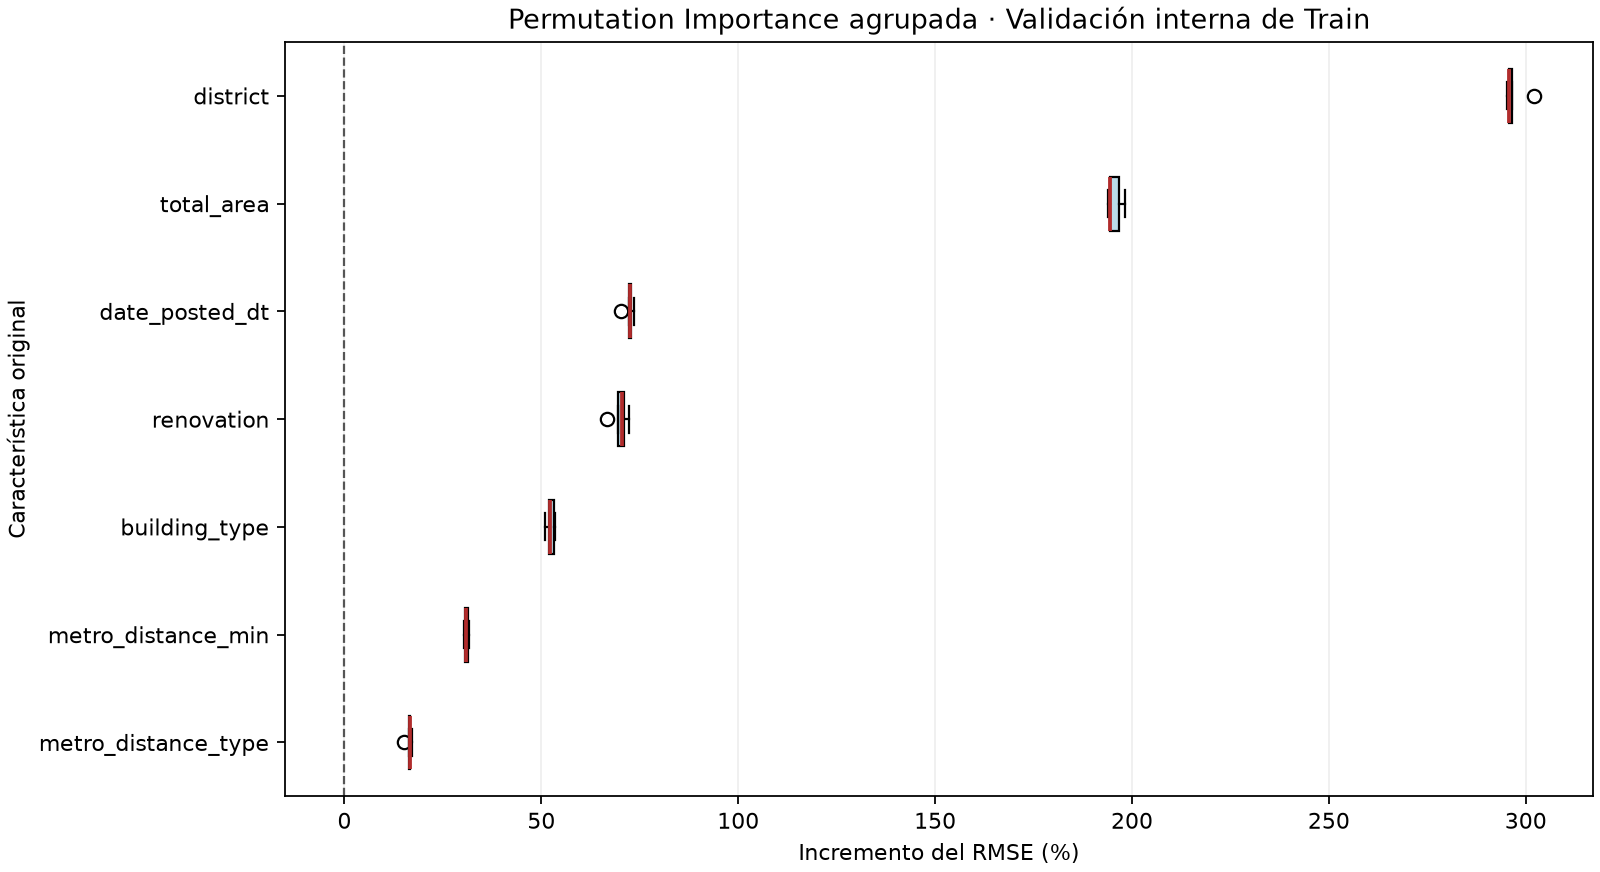

Mayores medianas de incremento del RMSE: `district` (295.7 %), `total_area` (194.5 %), `date_posted_dt` (72.5 %); 5 permutaciones por grupo.  
Las columnas de cada grupo se permutan conjuntamente respecto de price_rub; no mide efectos causales ni magnitudes de coeficientes OLS.  
Se reutiliza la validación de selección; correlaciones entre características pueden afectar la importancia.

In [6]:
display(Image(filename=str(forward['salida'] / 'importancia_caracteristicas_boxplot.png')))
display(Markdown(s.interpretar_importancia(forward)))


In [7]:
display(Markdown(s.confirmacion_presentacion(forward)))


Recuperado de MLflow; sin nueva selección ni ajuste final · **FINISHED** · [Forward_01_Log_Grupos](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/d43e88406b0843c5b7963d2c1e62d15a)

## 3. Group Lasso + OLS
La regularización selecciona grupos completos (incluidos los bloques One-Hot); después se ajusta un OLS sin penalización con las características elegidas.
Se evalúan **40 lambdas**, desde λmáx hasta 0,001 × λmáx. Los subconjuntos se comparan por RMSE interno en RUB, con máximo **12 grupos** y mejora mínima **0,5 %** entre complejidades aceptadas; se evalúa la grilla completa.
El escalado propio de la selección se ajusta solo en el entrenamiento interno; el OLS final conserva las escalas exportadas. Se comparte la partición de Forward.
El modo actual **recupera el Run histórico**; `modo="nuevo"` ejecuta la búsqueda y el OLS con un nombre de Run nuevo.


In [8]:
with sesion.paso():
    lasso = s.ejecutar_presentacion(datos, "lasso", modo=MODO, anterior=forward)


In [9]:
display(Markdown(lasso['caracteristicas_md']))


| Característica seleccionada | Cantidad de predictores |
|---|---|
| `total_area` | 1 |
| `ceiling_height` | 1 |
| `metro_distance_min` | 1 |
| `metro_to_center_km` | 1 |
| `surface_corrected` | 1 |
| `has_balcony` | 1 |
| `metro_distance_type` | 1 |
| `building_type` | 5 |
| `renovation` | 3 |
| `district` | 128 |
| `date_posted_dt` | 1 |
| Total: 11 características | 144 predictores |

In [10]:
display(Markdown(s.tabla_metricas_presentacion(lasso, anterior=forward)))


| Evaluación | Métrica | Forward | Group Lasso + OLS | Δ nuevo − anterior |
|---|---|---|---|---|
| Train | R² [ln(RUB)] | 0.953577 | 0.954765 | 0.001188 |
| Train | R² ajustado [ln(RUB)] | 0.953405 | 0.954592 | 0.001187 |
| Train | MAE (RUB) | 1,116,830.765 | 1,104,234.841 | -12,595.924 |
| Train | RMSE (RUB) | 1,609,441.446 | 1,592,884.139 | -16,557.307 |
| Train | AIC [ln(RUB)] | -52,883.105 | -53,859.677 | -976.572 |
| Train | BIC [ln(RUB)] | -51,678.271 | -52,620.664 | -942.393 |
| Train | VIF máximo | 8.554 | 10.369 | 1.815 |
| Train | Número de condición | 13,160.607 | 13,237.461 | 76.854 |
| Train | Breusch–Pagan (p) | 2.337e-87 | 8.128e-117 | -2.337e-87 |
| Train | Jarque–Bera (p) | 2.214e-65 | 2.745e-51 | 2.745e-51 |
| Validación interna | RMSE (RUB) | 1,612,615.151 | 1,593,947.716 | -18,667.436 |

In [11]:
display(Markdown(s.interpretar_presentacion(lasso, anterior=forward)))


El OLS utiliza 11 características originales y 144 columnas predictoras, más el intercepto.  
R² ajustado log=0.95459; RMSE Train=1,592,884 RUB y validación interna=1,593,948 RUB.  
Frente a Forward, cambia +4 características y el RMSE interno -1.158 %; no simplifica el modelo.  
Persisten límites de homocedasticidad (BP p=8.13e-117) y normalidad (JB p=2.75e-51).  
La validación se utilizó para seleccionar: sus métricas no son una evaluación independiente. exp sin corrección puede sesgar el precio esperado.

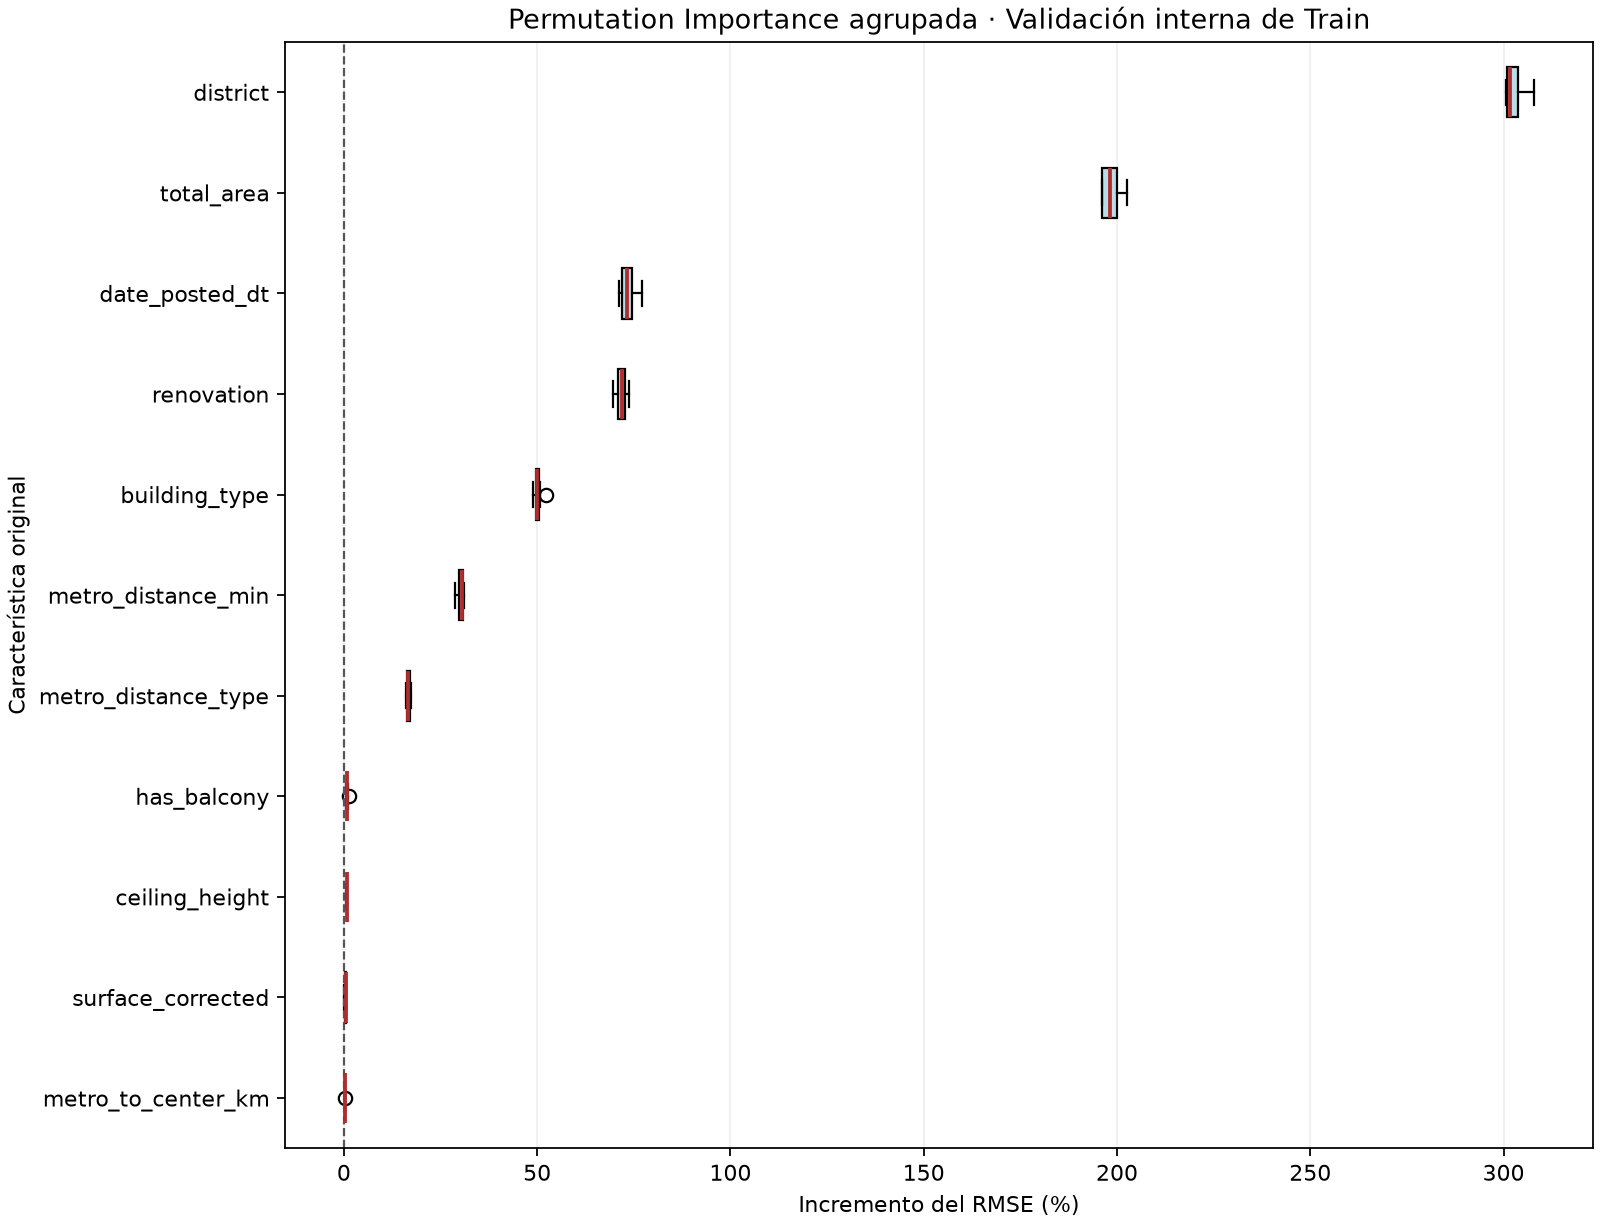

Mayores medianas de incremento del RMSE: `district` (301.7 %), `total_area` (198.3 %), `date_posted_dt` (73.3 %); 10 permutaciones por grupo.  
Las columnas de cada grupo se permutan conjuntamente respecto de price_rub; no mide efectos causales ni magnitudes de coeficientes OLS.  
Se reutiliza la validación de selección; correlaciones entre características pueden afectar la importancia.

In [12]:
display(Image(filename=str(lasso['salida'] / 'importancia_caracteristicas_boxplot.png')))
display(Markdown(s.interpretar_importancia(lasso)))


In [13]:
display(Markdown(s.confirmacion_presentacion(lasso)))


Recuperado de MLflow; sin nueva selección ni ajuste final · **FINISHED** · [GroupLasso_02_Log_Grupos_OLS](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/ac9faf6b61db4a7f8e274553199c5658)

## 4. Backward Selection
Parte de **177 columnas predictoras y un intercepto**, agrupadas por el linaje original; cada bloque One-Hot es indivisible. Referencia histórica: `OLS_02_Log_Target`.
En cada paso se elimina el grupo cuyo retiro produce el menor RMSE interno en RUB (`exp`, sin corrección), aun cuando implique deterioro. Se recorre hasta un grupo; después se evalúan los tamaños identificables de 1 a 12 en orden creciente, aceptando mejoras de al menos **0,5 %** frente al último aceptado, desde el intercepto. Un rechazo no detiene tamaños posteriores. No se eliminan columnas implícitamente por colinealidad; se registra el rango y el OLS definitivo debe ser identificable.
El Run exclusivo es `Backward_03_Log_177_Grupos_OLS`. La ejecución publicada se recupera con verificación estricta; una ejecución nueva requiere `modo="nuevo"` y un nombre libre. No se reentrenan los experimentos anteriores.


In [14]:
with sesion.paso():
    datos_backward = bw.cargar_datos(datos)
    backward = s.ejecutar_presentacion(datos_backward, "backward", modo="recuperar")


In [15]:
resumen, coeficientes = backward['caracteristicas_md'].split("\n\n", 1)
display(Markdown(resumen + "\n\n<details><summary>Columnas transformadas y coeficientes OLS</summary>\n\n"
                 + coeficientes + "\n\n</details>"))


| Característica seleccionada | Cantidad de predictores |
|---|---|
| `total_area` | 1 |
| `rooms` | 1 |
| `ceiling_height` | 1 |
| `metro_distance_min` | 1 |
| `to_center_km` | 1 |
| `surface_corrected` | 1 |
| `has_balcony` | 1 |
| `metro_distance_type` | 1 |
| `building_type` | 5 |
| `renovation` | 3 |
| `district` | 128 |
| `date_posted_dt` | 1 |
| Total: 12 características | 145 predictores |

<details><summary>Columnas transformadas y coeficientes OLS</summary>

| Característica original | Columna transformada | Coeficiente OLS [ln(RUB)] |
|---|---|---|
| total_area | total_area | 0.0158 |
| rooms | rooms | -0.0225 |
| ceiling_height | ceiling_height | 0.0456 |
| metro_distance_min | metro_distance_min | -0.0017 |
| to_center_km | to_center_km | -0.0078 |
| surface_corrected | surface_corrected | -0.1475 |
| has_balcony | has_balcony | 0.0309 |
| metro_distance_type | metro_distance_type | -0.1249 |
| building_type | building_type_khrushchev | -0.2102 |
| building_type | building_type_modern_panel | -0.0477 |
| building_type | building_type_monolith | 0.0454 |
| building_type | building_type_panel | -0.1322 |
| building_type | building_type_stalin | 0.1322 |
| renovation | renovation_designer | 0.3053 |
| renovation | renovation_euro | 0.1450 |
| renovation | renovation_no_renovation | -0.1110 |
| district | district_akademichesky | 0.1754 |
| district | district_alekseevsky | -0.0090 |
| district | district_altufyevsky | -0.2900 |
| district | district_arbat | 0.7328 |
| district | district_babushkinsky | -0.2064 |
| district | district_basmanny | 0.4852 |
| district | district_begovoy | 0.1387 |
| district | district_beskudnikovsky | -0.2679 |
| district | district_bibirevo | -0.2590 |
| district | district_biryulyovo_vostochnoye | -0.3662 |
| district | district_biryulyovo_zapadnoye | -0.3461 |
| district | district_bogorodskoye | -0.2132 |
| district | district_brateyevo | -0.3522 |
| district | district_butyrsky | -0.0668 |
| district | district_chertanovo_severnoye | -0.1933 |
| district | district_chertanovo_tsentralnoye | -0.2911 |
| district | district_chertanovo_yuzhnoye | -0.2024 |
| district | district_cheryomushki | 0.1799 |
| district | district_danilovsky | 0.0136 |
| district | district_desyonovskoye | -0.4765 |
| district | district_dmitrovsky | -0.3039 |
| district | district_donskoy | 0.0861 |
| district | district_dorogomilovo | 0.4668 |
| district | district_fili_davydkovo | 0.1820 |
| district | district_filimonkovskoye | -0.6095 |
| district | district_filyovsky_park | 0.2352 |
| district | district_gagarinsky | 0.3063 |
| district | district_golovinsky | -0.1959 |
| district | district_golyanovo | -0.2875 |
| district | district_ivanovskoye | -0.2787 |
| district | district_izmaylovo | -0.1124 |
| district | district_khamovniki | 0.7604 |
| district | district_khoroshyovo_mnyovniki | 0.1010 |
| district | district_khoroshyovsky | 0.1691 |
| district | district_khovrino | -0.2865 |
| district | district_kievsky | -0.5267 |
| district | district_klyonovskoye | -0.7022 |
| district | district_kokoshkino | -0.6138 |
| district | district_konkovo | 0.0240 |
| district | district_koptevo | -0.1861 |
| district | district_kosino_ukhtomsky | -0.3586 |
| district | district_kotlovka | 0.0692 |
| district | district_krasnopakhorskoye | -0.7580 |
| district | district_krasnoselsky | 0.4330 |
| district | district_krylatskoye | 0.2413 |
| district | district_kuntsevo | 0.0927 |
| district | district_kurkino | 0.0774 |
| district | district_levoberezhny | -0.1569 |
| district | district_lianozovo | -0.2879 |
| district | district_lomonosovsky | 0.3002 |
| district | district_losinoostrovsky | -0.2325 |
| district | district_marfino | -0.2210 |
| district | district_marushkinskoye | -0.6196 |
| district | district_maryina_roshcha | -0.0025 |
| district | district_meshchansky | 0.4762 |
| district | district_metrogorodok | -0.2752 |
| district | district_mikhaylovo_yartsevskoye | -0.7822 |
| district | district_mitino | -0.0607 |
| district | district_molzhaninovsky | -0.3541 |
| district | district_moskovsky | -0.4424 |
| district | district_moskvorechye_saburovo | -0.2254 |
| district | district_mosrentgen | -0.4054 |
| district | district_mozhaysky | 0.0164 |
| district | district_nagatino_sadovniki | -0.1233 |
| district | district_nagatinsky_zaton | -0.0938 |
| district | district_nagorny | -0.0607 |
| district | district_novo_peredelkino | -0.1646 |
| district | district_novofyodorovskoye | -0.5754 |
| district | district_novogireyevo | -0.1862 |
| district | district_novokosino | -0.2572 |
| district | district_obruchevsky | 0.1184 |
| district | district_ochakovo_matveyevskoye | 0.0111 |
| district | district_orekhovo_borisovo_severnoye | -0.3389 |
| district | district_orekhovo_borisovo_yuzhnoye | -0.3402 |
| district | district_ostankinsky | -0.0170 |
| district | district_otradnoye | -0.2159 |
| district | district_perovo | -0.0932 |
| district | district_pervomayskoye | -0.7127 |
| district | district_pokrovskoye_streshnevo | 0.0017 |
| district | district_preobrazhenskoye | -0.0413 |
| district | district_presnensky | 0.6805 |
| district | district_prospekt_vernadskogo | 0.3079 |
| district | district_ramenki | 0.3121 |
| district | district_rogovskoye | -0.5616 |
| district | district_rostokino | -0.2133 |
| district | district_ryazanovskoye | -0.5636 |
| district | district_savyolovsky | 0.0691 |
| district | district_severnoye_butovo | -0.1195 |
| district | district_severnoye_izmaylovo | -0.1517 |
| district | district_severnoye_medvedkovo | -0.2212 |
| district | district_severnoye_tushino | -0.1112 |
| district | district_severny | -0.3491 |
| district | district_shchapovskoye | -0.8357 |
| district | district_shcherbinka | -0.4657 |
| district | district_shchukino | 0.1878 |
| district | district_sokol | 0.1521 |
| district | district_sokolinaya_gora | -0.2184 |
| district | district_sokolniki | 0.0200 |
| district | district_solntsevo | -0.1093 |
| district | district_sosenskoye | -0.4350 |
| district | district_strogino | 0.2742 |
| district | district_sviblovo | -0.1775 |
| district | district_tagansky | 0.4445 |
| district | district_timiryazevsky | -0.0318 |
| district | district_troitsk | -0.6331 |
| district | district_troparyovo_nikulino | 0.2422 |
| district | district_tsaritsyno | -0.3001 |
| district | district_tverskoy | 0.7221 |
| district | district_tyoply_stan | -0.0312 |
| district | district_veshnyaki | -0.3671 |
| district | district_vnukovo | -0.1642 |
| district | district_vnukovskoye | -0.4366 |
| district | district_voronovskoye | -0.6237 |
| district | district_voskresenskoye | -0.5224 |
| district | district_vostochnoye_izmaylovo | -0.2178 |
| district | district_vostochny | -0.3772 |
| district | district_voykovsky | -0.0633 |
| district | district_yakimanka | 0.6752 |
| district | district_yaroslavsky | -0.2539 |
| district | district_yasenevo | 0.1463 |
| district | district_yuzhnoye_butovo | -0.1467 |
| district | district_yuzhnoye_medvedkovo | -0.2607 |
| district | district_yuzhnoye_tushino | -0.0547 |
| district | district_zamoskvorechye | 0.5589 |
| district | district_zapadnoye_degunino | -0.2978 |
| district | district_zelenograd | -0.4443 |
| district | district_zyablikovo | -0.3275 |
| district | district_zyuzino | 0.0295 |
| date_posted_dt | months_since_start | 0.0073 |

</details>

In [16]:
display(Markdown(s.tabla_metricas_presentacion(backward)))


| Evaluación | Métrica | Backward Selection |
|---|---|---|
| Train | R² [ln(RUB)] | 0.955399 |
| Train | R² ajustado [ln(RUB)] | 0.955228 |
| Train | MAE (RUB) | 1,096,985.003 |
| Train | RMSE (RUB) | 1,581,589.473 |
| Train | AIC [ln(RUB)] | -54,393.951 |
| Train | BIC [ln(RUB)] | -53,146.392 |
| Train | VIF máximo | 102.537 |
| Train | Número de condición | 17,434.006 |
| Train | Breusch–Pagan (p) | 3.724e-117 |
| Train | Jarque–Bera (p) | 1.253e-42 |
| Validación interna | RMSE (RUB) | 1,581,085.284 |

In [17]:
display(Markdown(s.interpretar_presentacion(backward)))


El OLS utiliza 12 características originales y 145 columnas predictoras, más el intercepto.  
R² ajustado log=0.95523; RMSE Train=1,581,589 RUB y validación interna=1,581,085 RUB.  
Persisten límites de homocedasticidad (BP p=3.72e-117) y normalidad (JB p=1.25e-42).  
La validación se utilizó para seleccionar: sus métricas no son una evaluación independiente. exp sin corrección puede sesgar el precio esperado.

In [18]:
display(Markdown(bw.resumen_trayectoria(backward)))
display(Markdown(bw.tabla_trayectoria(backward)))


Inicio: 23 características originales, 177 columnas más intercepto; rango efectivo 178/178. Advertencias iniciales: ninguna.  
Trayectoria completa: 22 eliminaciones y 275 candidatos. Orden de eliminación: `secondary_mom_change_pct`, `total_floors`, `living_area`, `seller_type`, `building_year`, `kitchen_area`, `metro_to_center_km`, `month_of_year`, `mortgage_key_rate_at_listing`, `floor`, `metro_line`, `surface_corrected`, `to_center_km`, `has_balcony`, `ceiling_height`, `rooms`, `metro_distance_type`, `metro_distance_min`, `building_type`, `date_posted_dt`, `renovation`, `total_area`.  
RMSE interno: inicial 1,575,110, mínimo de trayectoria 1,573,683, un grupo 4,006,722 RUB. Seleccionado: 1,581,085 RUB.  
Se evaluaron los tamaños identificables de 1 a 12 en orden creciente, desde el intercepto; cada aceptación exige una mejora ≥0,5 % frente al último aceptado. Un rechazo no detiene la evaluación.

| Grupos | Columnas | RMSE interno (RUB) | Rango | Aceptado |
|---|---|---|---|---|
| 1 | 128 | 4,006,722.075 | 129 | True |
| 2 | 129 | 3,072,722.644 | 130 | True |
| 3 | 132 | 2,725,971.347 | 133 | True |
| 4 | 133 | 2,296,175.987 | 134 | True |
| 5 | 138 | 1,890,591.402 | 139 | True |
| 6 | 139 | 1,692,372.619 | 140 | True |
| 7 | 140 | 1,612,615.151 | 141 | True |
| 8 | 141 | 1,603,607.587 | 142 | True |
| 9 | 142 | 1,596,437.554 | 143 | False |
| 10 | 143 | 1,590,075.437 | 144 | True |
| 11 | 144 | 1,584,779.019 | 145 | False |
| 12 | 145 | 1,581,085.284 | 146 | True |

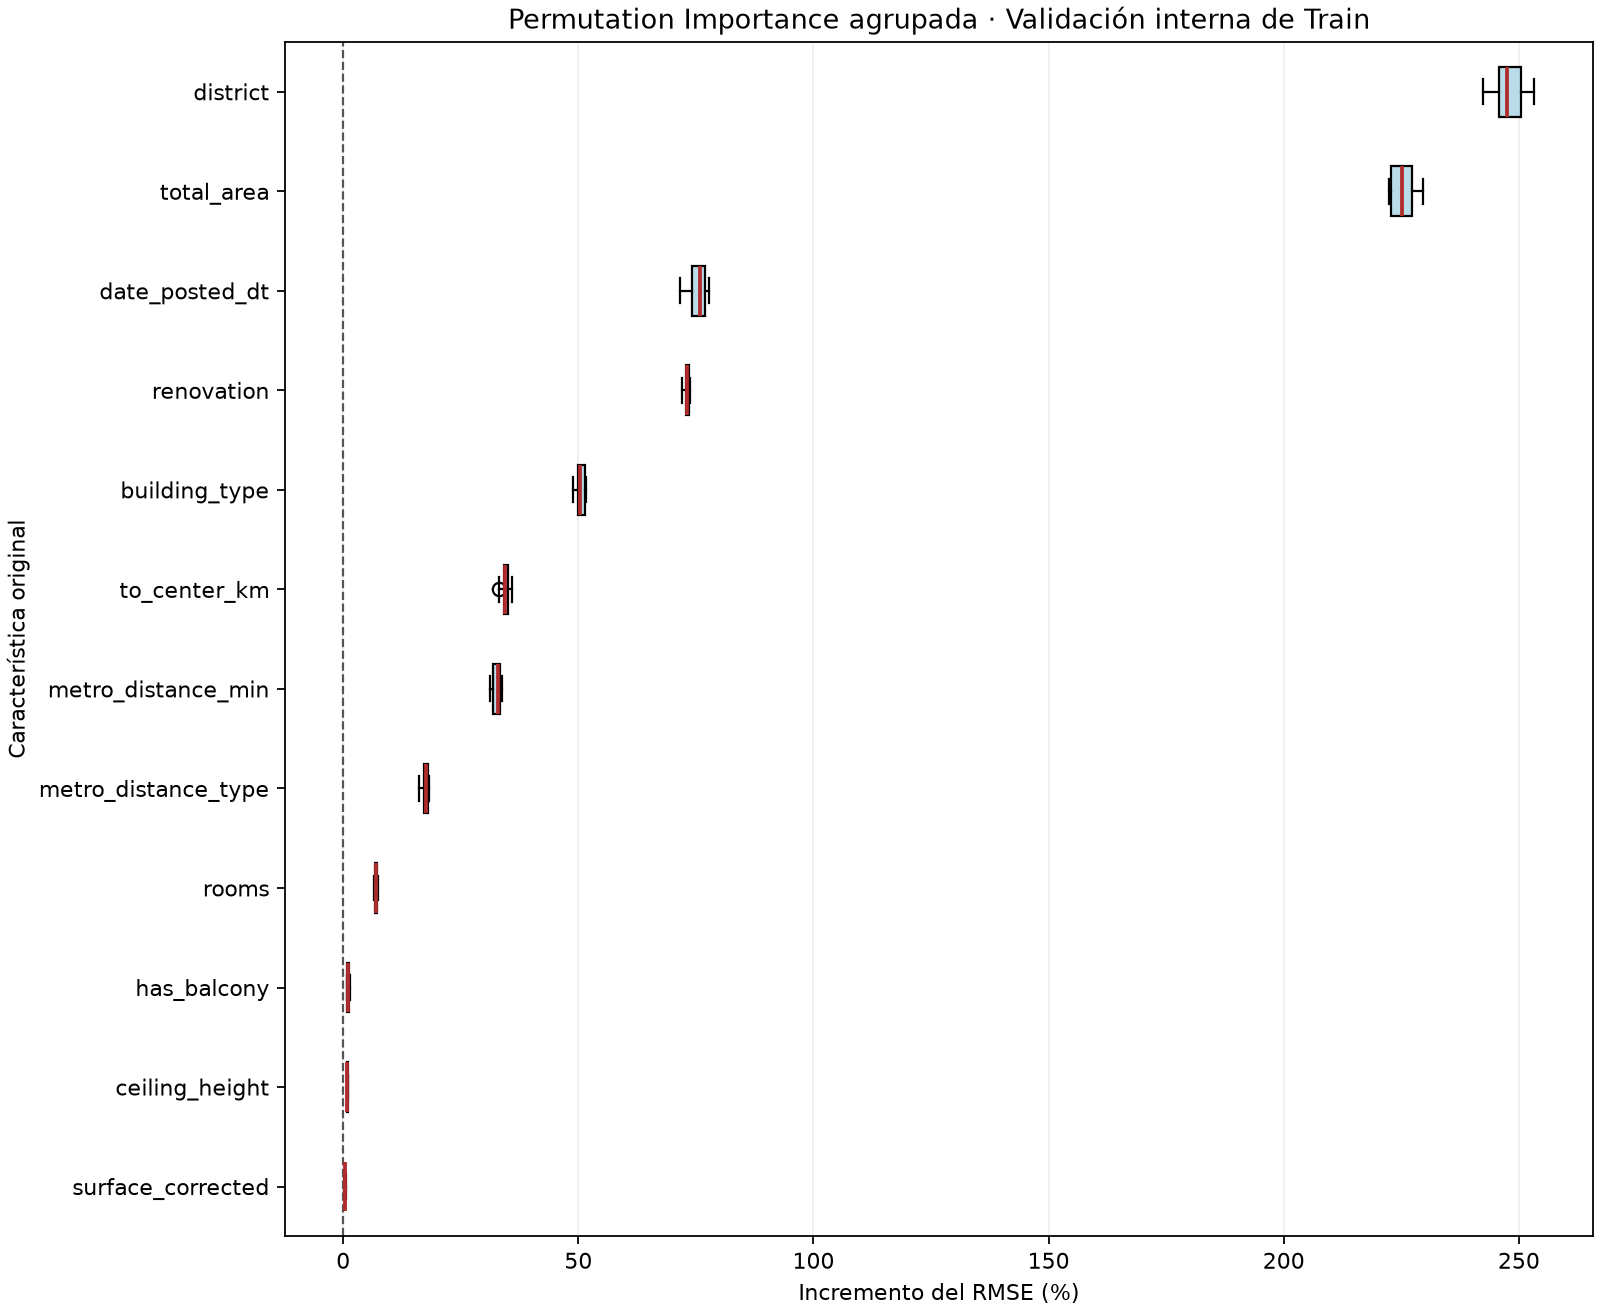

Mayores medianas de incremento del RMSE: `district` (247.4 %), `total_area` (225.2 %), `date_posted_dt` (75.9 %); 10 permutaciones por grupo.  
Las columnas de cada grupo se permutan conjuntamente respecto de price_rub; no mide efectos causales ni magnitudes de coeficientes OLS.  
Se reutiliza la validación de selección; correlaciones entre características pueden afectar la importancia.

In [19]:
display(Image(filename=str(backward['salida'] / 'importancia_caracteristicas_boxplot.png')))
display(Markdown(s.interpretar_importancia(backward)))


In [20]:
display(Markdown(s.confirmacion_presentacion(backward)))


Recuperado de MLflow; sin nueva selección ni ajuste final · **FINISHED** · [Backward_03_Log_177_Grupos_OLS](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/74f261e8575b4858ad9a88fd9373bc76)

## 5. Forward Stepwise Selection — 177 predictoras
Experimento independiente del Forward histórico: **177 columnas candidatas / 23 características originales**, incluidas `to_center_km`, `living_area` y `rooms`, con exclusiones vacías. Se reutiliza el algoritmo agrupado de `scripts/seleccion_modelos.py`; los bloques One-Hot ingresan completos.
Desde el intercepto, cada incorporación debe mejorar el RMSE interno en RUB al menos **0,5 %** frente al modelo anterior. Se detiene en el primer rechazo, al alcanzar **12 grupos** o al agotar las candidatas. La partición es exactamente la misma (80/20, semilla 42); objetivo `ln(price_rub)`, inversa `exp`, sin corrección de sesgo. El OLS definitivo se reajusta con todo Train y debe presentar rango completo.
Referencia: `OLS_02_Log_Target` (177 predictoras). Run exclusivo: `Forward_04_Log_177_Grupos`. Una ejecución nueva exige `modo="nuevo"` y un nombre libre; tras el registro, se recupera estrictamente sin repetir la selección ni el ajuste final. Los CSV y los modelos anteriores se conservan.


In [21]:
with sesion.paso():
    datos_forward_177 = s.cargar_forward_177(datos)
    forward_177 = s.ejecutar_presentacion(datos_forward_177, "forward", modo="recuperar", nombre_run=s.NOMBRE_RUN_177)


In [22]:
resumen_177, coeficientes_177 = forward_177['caracteristicas_md'].split("\n\n", 1)
display(Markdown(resumen_177 + "\n\n<details><summary>Columnas transformadas y coeficientes OLS</summary>\n\n"
                 + coeficientes_177 + "\n\n</details>"))


| Orden | Característica seleccionada | Cantidad de predictores |
|---|---|---|
| 1 | `district` | 128 |
| 2 | `total_area` | 1 |
| 3 | `renovation` | 3 |
| 4 | `date_posted_dt` | 1 |
| 5 | `building_type` | 5 |
| 6 | `metro_distance_min` | 1 |
| 7 | `metro_distance_type` | 1 |
| 8 | `rooms` | 1 |
| Total | 8 características | 141 predictores |

<details><summary>Columnas transformadas y coeficientes OLS</summary>

| Característica original | Columna transformada | Coeficiente OLS [ln(RUB)] |
|---|---|---|
| district | district_akademichesky | 0.1738 |
| district | district_alekseevsky | 0.0019 |
| district | district_altufyevsky | -0.3459 |
| district | district_arbat | 0.7782 |
| district | district_babushkinsky | -0.2468 |
| district | district_basmanny | 0.5165 |
| district | district_begovoy | 0.1548 |
| district | district_beskudnikovsky | -0.3153 |
| district | district_bibirevo | -0.3091 |
| district | district_biryulyovo_vostochnoye | -0.4538 |
| district | district_biryulyovo_zapadnoye | -0.4253 |
| district | district_bogorodskoye | -0.2254 |
| district | district_brateyevo | -0.4078 |
| district | district_butyrsky | -0.0635 |
| district | district_chertanovo_severnoye | -0.2226 |
| district | district_chertanovo_tsentralnoye | -0.3363 |
| district | district_chertanovo_yuzhnoye | -0.2750 |
| district | district_cheryomushki | 0.1643 |
| district | district_danilovsky | 0.0326 |
| district | district_desyonovskoye | -0.6320 |
| district | district_dmitrovsky | -0.3583 |
| district | district_donskoy | 0.1078 |
| district | district_dorogomilovo | 0.4881 |
| district | district_fili_davydkovo | 0.1699 |
| district | district_filimonkovskoye | -0.7517 |
| district | district_filyovsky_park | 0.2233 |
| district | district_gagarinsky | 0.3163 |
| district | district_golovinsky | -0.2333 |
| district | district_golyanovo | -0.3298 |
| district | district_ivanovskoye | -0.3180 |
| district | district_izmaylovo | -0.1345 |
| district | district_khamovniki | 0.7899 |
| district | district_khoroshyovo_mnyovniki | 0.0875 |
| district | district_khoroshyovsky | 0.1805 |
| district | district_khovrino | -0.3473 |
| district | district_kievsky | -0.9929 |
| district | district_klyonovskoye | -1.0697 |
| district | district_kokoshkino | -0.7746 |
| district | district_konkovo | -0.0264 |
| district | district_koptevo | -0.2183 |
| district | district_kosino_ukhtomsky | -0.4123 |
| district | district_kotlovka | 0.0580 |
| district | district_krasnopakhorskoye | -1.0113 |
| district | district_krasnoselsky | 0.4597 |
| district | district_krylatskoye | 0.2014 |
| district | district_kuntsevo | 0.0626 |
| district | district_kurkino | -0.0254 |
| district | district_levoberezhny | -0.2141 |
| district | district_lianozovo | -0.3574 |
| district | district_lomonosovsky | 0.2952 |
| district | district_losinoostrovsky | -0.2830 |
| district | district_marfino | -0.2384 |
| district | district_marushkinskoye | -0.7989 |
| district | district_maryina_roshcha | 0.0212 |
| district | district_meshchansky | 0.5120 |
| district | district_metrogorodok | -0.3007 |
| district | district_mikhaylovo_yartsevskoye | -1.0793 |
| district | district_mitino | -0.1520 |
| district | district_molzhaninovsky | -0.4932 |
| district | district_moskovsky | -0.5689 |
| district | district_moskvorechye_saburovo | -0.2603 |
| district | district_mosrentgen | -0.4778 |
| district | district_mozhaysky | -0.0274 |
| district | district_nagatino_sadovniki | -0.1257 |
| district | district_nagatinsky_zaton | -0.1034 |
| district | district_nagorny | -0.0710 |
| district | district_novo_peredelkino | -0.2597 |
| district | district_novofyodorovskoye | -1.0091 |
| district | district_novogireyevo | -0.2142 |
| district | district_novokosino | -0.3153 |
| district | district_obruchevsky | 0.0904 |
| district | district_ochakovo_matveyevskoye | -0.0211 |
| district | district_orekhovo_borisovo_severnoye | -0.3964 |
| district | district_orekhovo_borisovo_yuzhnoye | -0.4101 |
| district | district_ostankinsky | -0.0185 |
| district | district_otradnoye | -0.2513 |
| district | district_perovo | -0.1143 |
| district | district_pervomayskoye | -1.0224 |
| district | district_pokrovskoye_streshnevo | -0.0361 |
| district | district_preobrazhenskoye | -0.0404 |
| district | district_presnensky | 0.7159 |
| district | district_prospekt_vernadskogo | 0.2774 |
| district | district_ramenki | 0.3000 |
| district | district_rogovskoye | -1.0096 |
| district | district_rostokino | -0.2294 |
| district | district_ryazanovskoye | -0.7529 |
| district | district_savyolovsky | 0.0888 |
| district | district_severnoye_butovo | -0.2079 |
| district | district_severnoye_izmaylovo | -0.1918 |
| district | district_severnoye_medvedkovo | -0.2747 |
| district | district_severnoye_tushino | -0.1770 |
| district | district_severny | -0.4430 |
| district | district_shchapovskoye | -1.1066 |
| district | district_shcherbinka | -0.6256 |
| district | district_shchukino | 0.1613 |
| district | district_sokol | 0.1430 |
| district | district_sokolinaya_gora | -0.2211 |
| district | district_sokolniki | 0.0369 |
| district | district_solntsevo | -0.1921 |
| district | district_sosenskoye | -0.5679 |
| district | district_strogino | 0.2190 |
| district | district_sviblovo | -0.2016 |
| district | district_tagansky | 0.4755 |
| district | district_timiryazevsky | -0.0325 |
| district | district_troitsk | -0.8561 |
| district | district_troparyovo_nikulino | 0.1928 |
| district | district_tsaritsyno | -0.3575 |
| district | district_tverskoy | 0.7624 |
| district | district_tyoply_stan | -0.1027 |
| district | district_veshnyaki | -0.4033 |
| district | district_vnukovo | -0.2990 |
| district | district_vnukovskoye | -0.5516 |
| district | district_voronovskoye | -1.0033 |
| district | district_voskresenskoye | -0.6456 |
| district | district_vostochnoye_izmaylovo | -0.2604 |
| district | district_vostochny | -0.4423 |
| district | district_voykovsky | -0.0830 |
| district | district_yakimanka | 0.7129 |
| district | district_yaroslavsky | -0.3067 |
| district | district_yasenevo | 0.0731 |
| district | district_yuzhnoye_butovo | -0.2715 |
| district | district_yuzhnoye_medvedkovo | -0.3057 |
| district | district_yuzhnoye_tushino | -0.1099 |
| district | district_zamoskvorechye | 0.6021 |
| district | district_zapadnoye_degunino | -0.3417 |
| district | district_zelenograd | -0.6724 |
| district | district_zyablikovo | -0.3991 |
| district | district_zyuzino | 0.0052 |
| total_area | total_area | 0.0159 |
| renovation | renovation_designer | 0.3053 |
| renovation | renovation_euro | 0.1453 |
| renovation | renovation_no_renovation | -0.1108 |
| date_posted_dt | months_since_start | 0.0073 |
| building_type | building_type_khrushchev | -0.2104 |
| building_type | building_type_modern_panel | -0.0481 |
| building_type | building_type_monolith | 0.0453 |
| building_type | building_type_panel | -0.1327 |
| building_type | building_type_stalin | 0.1541 |
| metro_distance_min | metro_distance_min | -0.0017 |
| metro_distance_type | metro_distance_type | -0.1251 |
| rooms | rooms | -0.0236 |

</details>

In [23]:
display(Markdown(s.tabla_metricas_presentacion(forward_177)))


| Evaluación | Métrica | Forward Stepwise Selection — 177 predictoras |
|---|---|---|
| Train | R² [ln(RUB)] | 0.953968 |
| Train | R² ajustado [ln(RUB)] | 0.953796 |
| Train | MAE (RUB) | 1,113,229.451 |
| Train | RMSE (RUB) | 1,602,567.630 |
| Train | AIC [ln(RUB)] | -53,202.517 |
| Train | BIC [ln(RUB)] | -51,989.138 |
| Train | VIF máximo | 8.554 |
| Train | Número de condición | 13,163.344 |
| Train | Breusch–Pagan (p) | 2.275e-106 |
| Train | Jarque–Bera (p) | 1.516e-53 |
| Validación interna | RMSE (RUB) | 1,603,607.587 |

In [24]:
display(Markdown(s.interpretar_presentacion(forward_177)))


El OLS utiliza 8 características originales y 141 columnas predictoras, más el intercepto.  
R² ajustado log=0.95380; RMSE Train=1,602,568 RUB y validación interna=1,603,608 RUB.  
Persisten límites de homocedasticidad (BP p=2.28e-106) y normalidad (JB p=1.52e-53).  
La validación se utilizó para seleccionar: sus métricas no son una evaluación independiente. exp sin corrección puede sesgar el precio esperado.

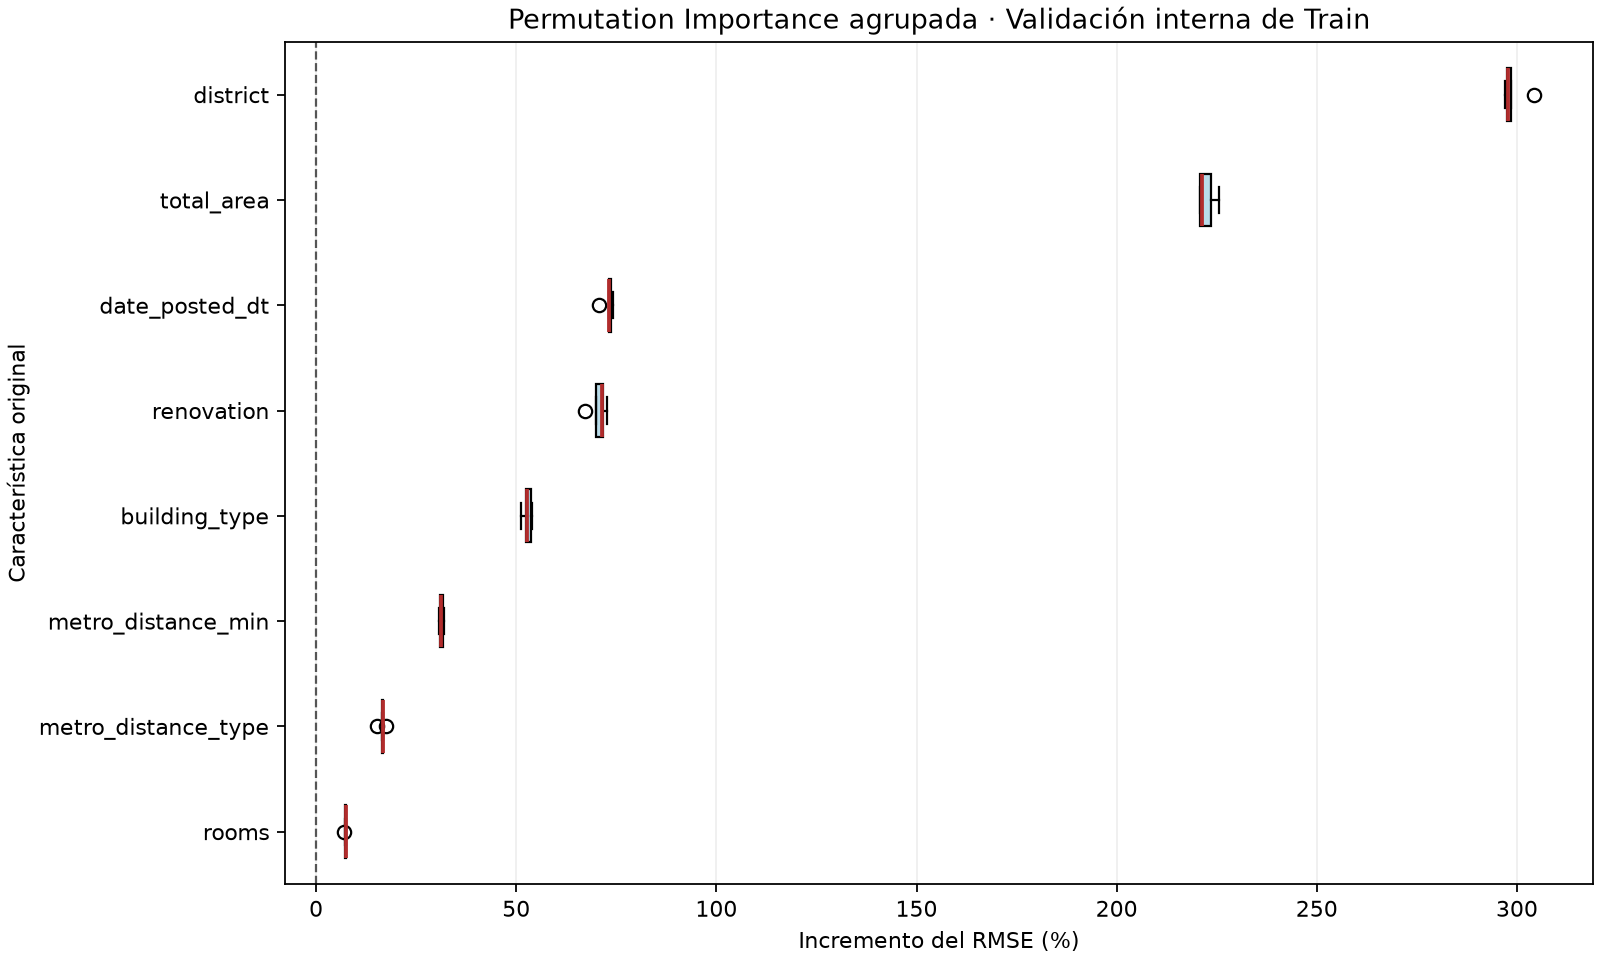

Mayores medianas de incremento del RMSE: `district` (297.7 %), `total_area` (221.2 %), `date_posted_dt` (73.2 %); 5 permutaciones por grupo.  
Las columnas de cada grupo se permutan conjuntamente respecto de price_rub; no mide efectos causales ni magnitudes de coeficientes OLS.  
Se reutiliza la validación de selección; correlaciones entre características pueden afectar la importancia.

In [25]:
display(Image(filename=str(forward_177['salida'] / 'importancia_caracteristicas_boxplot.png')))
display(Markdown(s.interpretar_importancia(forward_177)))


In [26]:
display(Markdown(s.confirmacion_presentacion(forward_177)))


Recuperado de MLflow; sin nueva selección ni ajuste final · **FINISHED** · [Forward_04_Log_177_Grupos](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/9b5b90c245cb4fd8a804c1d0e4c3ff7b)

### Comparación específica: Forward de 174 y 177 predictoras
El algoritmo y la configuración se mantienen. Se distingue el universo disponible del subconjunto elegido y se informa cuándo ingresan las tres características habilitadas.


In [27]:
tabla_forward_177, analisis_forward_177 = s.comparacion_forward_presentacion(forward, forward_177)
display(Markdown(tabla_forward_177))
display(Markdown(analisis_forward_177))


| Método | Características | Columnas OLS | R² ajustado Train [log] | RMSE Train (RUB) | RMSE interno (RUB) | AIC [log] | BIC [log] |
|---|---|---|---|---|---|---|---|
| Forward Stepwise Selection — 174 predictoras | 7 | 140 | 0.953405 | 1,609,441.446 | 1,612,615.151 | -52,883.105 | -51,678.271 |
| Forward Stepwise Selection — 177 predictoras | 8 | 141 | 0.953796 | 1,602,567.630 | 1,603,607.587 | -53,202.517 | -51,989.138 |
| Δ 177 − 174 | 1.000 | 1.000 | 3.914e-04 | -6,873.815 | -9,007.565 | -319.412 | -310.867 |

Universos iniciales: 174 columnas / 20 grupos frente a 177 columnas / 23 grupos. La tabla cuenta las características y columnas finales.  
Comunes: `building_type`, `date_posted_dt`, `district`, `metro_distance_min`, `metro_distance_type`, `renovation`, `total_area`. Exclusivas del histórico: Ninguna. Exclusivas del nuevo: `rooms`.  
`to_center_km`: disponible entre las candidatas, no seleccionada.  
`living_area`: disponible entre las candidatas, no seleccionada.  
`rooms`: incorporada en la iteración 8.  
Cambio del RMSE interno: -9,007.565 RUB (-0.559 %). Habilitar las tres variables reduce el error observado de selección. El conjunto seleccionado cambia.  
La validación interna se utilizó para seleccionar los modelos; no es una evaluación independiente sobre datos nuevos. Test no se utilizó.

## 6. Group Lasso + OLS — 177 predictoras
Experimento independiente: **177 columnas / 23 grupos originales**, incluidas `to_center_km`, `living_area` y `rooms`, sin exclusiones previas. Los bloques One-Hot se seleccionan completos. Referencia obligatoria: `Forward_04_Log_177_Grupos`, terminado y con los mismos índices internos 80/20 (semilla 42).
Se conserva Group Lasso ponderado por la raíz del rango de cada grupo: centrado del objetivo e intercepto sin penalización, `StandardScaler` ajustado solo en entrenamiento interno, FISTA con reinicio adaptativo y verificación KKT. Se recorren **40 lambdas**, de λmax a 0,001 × λmax; tolerancias de soporte 1e-6 y solver 1e-7, máximo 20.000 iteraciones.
Se comparan los mejores subconjuntos de cada tamaño de **1 a 12 grupos** en orden creciente, desde el intercepto, aceptando mejoras del RMSE interno ≥0,5 % frente al último aceptado. Un rechazo no detiene tamaños posteriores. Se conserva la grilla completa, incluidos los modelos no elegibles con más de 12 grupos. Sin ganador o convergencia no se registra un modelo válido.
El OLS definitivo se ajusta sin penalización con todo Train, sobre las escalas exportadas; objetivo `ln(price_rub)`, inversa `exp` sin corrección de sesgo, diseño de rango completo. El Run exclusivo es `GroupLasso_05_Log_177_Grupos_OLS`; una ejecución nueva requiere un nombre libre. Tras su registro, se recupera estrictamente sin volver a entrenar. Test no se utiliza.


In [28]:
with sesion.paso():
    datos_lasso_177 = s.cargar_presentacion(base, sesion, excluidas=(), cliente=datos['cliente'])
    lasso_177 = s.ejecutar_presentacion(datos_lasso_177, "lasso", modo="recuperar", anterior=forward_177,
                                      nombre_run=gl.NOMBRE_RUN_177)


In [29]:
resumen_lasso_177, coeficientes_lasso_177 = lasso_177['caracteristicas_md'].split("\n\n", 1)
display(Markdown(resumen_lasso_177 + "\n\n<details><summary>Columnas transformadas y coeficientes OLS</summary>\n\n"
                 + coeficientes_lasso_177 + "\n\n</details>"))


| Característica seleccionada | Cantidad de predictores |
|---|---|
| `total_area` | 1 |
| `living_area` | 1 |
| `ceiling_height` | 1 |
| `metro_distance_min` | 1 |
| `to_center_km` | 1 |
| `surface_corrected` | 1 |
| `has_balcony` | 1 |
| `metro_distance_type` | 1 |
| `building_type` | 5 |
| `renovation` | 3 |
| `district` | 128 |
| `date_posted_dt` | 1 |
| Total: 12 características | 145 predictores |

<details><summary>Columnas transformadas y coeficientes OLS</summary>

| Característica original | Columna transformada | Coeficiente OLS [ln(RUB)] |
|---|---|---|
| total_area | total_area | 0.0145 |
| living_area | living_area | 0.0002 |
| ceiling_height | ceiling_height | 0.0454 |
| metro_distance_min | metro_distance_min | -0.0017 |
| to_center_km | to_center_km | -0.0077 |
| surface_corrected | surface_corrected | -0.1577 |
| has_balcony | has_balcony | 0.0308 |
| metro_distance_type | metro_distance_type | -0.1249 |
| building_type | building_type_khrushchev | -0.2103 |
| building_type | building_type_modern_panel | -0.0479 |
| building_type | building_type_monolith | 0.0454 |
| building_type | building_type_panel | -0.1322 |
| building_type | building_type_stalin | 0.1324 |
| renovation | renovation_designer | 0.3051 |
| renovation | renovation_euro | 0.1450 |
| renovation | renovation_no_renovation | -0.1110 |
| district | district_akademichesky | 0.1765 |
| district | district_alekseevsky | -0.0071 |
| district | district_altufyevsky | -0.2884 |
| district | district_arbat | 0.7334 |
| district | district_babushkinsky | -0.2061 |
| district | district_basmanny | 0.4872 |
| district | district_begovoy | 0.1405 |
| district | district_beskudnikovsky | -0.2663 |
| district | district_bibirevo | -0.2581 |
| district | district_biryulyovo_vostochnoye | -0.3670 |
| district | district_biryulyovo_zapadnoye | -0.3459 |
| district | district_bogorodskoye | -0.2123 |
| district | district_brateyevo | -0.3522 |
| district | district_butyrsky | -0.0660 |
| district | district_chertanovo_severnoye | -0.1931 |
| district | district_chertanovo_tsentralnoye | -0.2896 |
| district | district_chertanovo_yuzhnoye | -0.2023 |
| district | district_cheryomushki | 0.1802 |
| district | district_danilovsky | 0.0141 |
| district | district_desyonovskoye | -0.4762 |
| district | district_dmitrovsky | -0.3021 |
| district | district_donskoy | 0.0879 |
| district | district_dorogomilovo | 0.4679 |
| district | district_fili_davydkovo | 0.1821 |
| district | district_filimonkovskoye | -0.6099 |
| district | district_filyovsky_park | 0.2369 |
| district | district_gagarinsky | 0.3070 |
| district | district_golovinsky | -0.1951 |
| district | district_golyanovo | -0.2869 |
| district | district_ivanovskoye | -0.2782 |
| district | district_izmaylovo | -0.1119 |
| district | district_khamovniki | 0.7616 |
| district | district_khoroshyovo_mnyovniki | 0.1026 |
| district | district_khoroshyovsky | 0.1693 |
| district | district_khovrino | -0.2858 |
| district | district_kievsky | -0.5299 |
| district | district_klyonovskoye | -0.7057 |
| district | district_kokoshkino | -0.6138 |
| district | district_konkovo | 0.0243 |
| district | district_koptevo | -0.1862 |
| district | district_kosino_ukhtomsky | -0.3578 |
| district | district_kotlovka | 0.0693 |
| district | district_krasnopakhorskoye | -0.7587 |
| district | district_krasnoselsky | 0.4354 |
| district | district_krylatskoye | 0.2424 |
| district | district_kuntsevo | 0.0925 |
| district | district_kurkino | 0.0766 |
| district | district_levoberezhny | -0.1573 |
| district | district_lianozovo | -0.2873 |
| district | district_lomonosovsky | 0.3022 |
| district | district_losinoostrovsky | -0.2323 |
| district | district_marfino | -0.2205 |
| district | district_marushkinskoye | -0.6189 |
| district | district_maryina_roshcha | -0.0010 |
| district | district_meshchansky | 0.4778 |
| district | district_metrogorodok | -0.2744 |
| district | district_mikhaylovo_yartsevskoye | -0.7841 |
| district | district_mitino | -0.0605 |
| district | district_molzhaninovsky | -0.3537 |
| district | district_moskovsky | -0.4426 |
| district | district_moskvorechye_saburovo | -0.2254 |
| district | district_mosrentgen | -0.4055 |
| district | district_mozhaysky | 0.0163 |
| district | district_nagatino_sadovniki | -0.1218 |
| district | district_nagatinsky_zaton | -0.0925 |
| district | district_nagorny | -0.0598 |
| district | district_novo_peredelkino | -0.1641 |
| district | district_novofyodorovskoye | -0.5787 |
| district | district_novogireyevo | -0.1853 |
| district | district_novokosino | -0.2565 |
| district | district_obruchevsky | 0.1196 |
| district | district_ochakovo_matveyevskoye | 0.0128 |
| district | district_orekhovo_borisovo_severnoye | -0.3385 |
| district | district_orekhovo_borisovo_yuzhnoye | -0.3389 |
| district | district_ostankinsky | -0.0151 |
| district | district_otradnoye | -0.2147 |
| district | district_perovo | -0.0931 |
| district | district_pervomayskoye | -0.7139 |
| district | district_pokrovskoye_streshnevo | 0.0031 |
| district | district_preobrazhenskoye | -0.0406 |
| district | district_presnensky | 0.6822 |
| district | district_prospekt_vernadskogo | 0.3098 |
| district | district_ramenki | 0.3137 |
| district | district_rogovskoye | -0.5645 |
| district | district_rostokino | -0.2127 |
| district | district_ryazanovskoye | -0.5641 |
| district | district_savyolovsky | 0.0706 |
| district | district_severnoye_butovo | -0.1195 |
| district | district_severnoye_izmaylovo | -0.1503 |
| district | district_severnoye_medvedkovo | -0.2210 |
| district | district_severnoye_tushino | -0.1114 |
| district | district_severny | -0.3487 |
| district | district_shchapovskoye | -0.8381 |
| district | district_shcherbinka | -0.4661 |
| district | district_shchukino | 0.1888 |
| district | district_sokol | 0.1534 |
| district | district_sokolinaya_gora | -0.2172 |
| district | district_sokolniki | 0.0219 |
| district | district_solntsevo | -0.1095 |
| district | district_sosenskoye | -0.4355 |
| district | district_strogino | 0.2747 |
| district | district_sviblovo | -0.1780 |
| district | district_tagansky | 0.4465 |
| district | district_timiryazevsky | -0.0308 |
| district | district_troitsk | -0.6343 |
| district | district_troparyovo_nikulino | 0.2421 |
| district | district_tsaritsyno | -0.3004 |
| district | district_tverskoy | 0.7230 |
| district | district_tyoply_stan | -0.0308 |
| district | district_veshnyaki | -0.3669 |
| district | district_vnukovo | -0.1641 |
| district | district_vnukovskoye | -0.4368 |
| district | district_voronovskoye | -0.6261 |
| district | district_voskresenskoye | -0.5223 |
| district | district_vostochnoye_izmaylovo | -0.2178 |
| district | district_vostochny | -0.3766 |
| district | district_voykovsky | -0.0625 |
| district | district_yakimanka | 0.6760 |
| district | district_yaroslavsky | -0.2530 |
| district | district_yasenevo | 0.1471 |
| district | district_yuzhnoye_butovo | -0.1464 |
| district | district_yuzhnoye_medvedkovo | -0.2598 |
| district | district_yuzhnoye_tushino | -0.0549 |
| district | district_zamoskvorechye | 0.5592 |
| district | district_zapadnoye_degunino | -0.2970 |
| district | district_zelenograd | -0.4451 |
| district | district_zyablikovo | -0.3275 |
| district | district_zyuzino | 0.0304 |
| date_posted_dt | months_since_start | 0.0073 |

</details>

In [30]:
display(Markdown(s.tabla_metricas_presentacion(lasso_177, anterior=forward_177)))


| Evaluación | Métrica | Forward Stepwise Selection — 177 predictoras | Group Lasso + OLS — 177 predictoras | Δ nuevo − anterior |
|---|---|---|---|---|
| Train | R² [ln(RUB)] | 0.953968 | 0.955048 | 0.001080 |
| Train | R² ajustado [ln(RUB)] | 0.953796 | 0.954876 | 0.001080 |
| Train | MAE (RUB) | 1,113,229.451 | 1,100,663.681 | -12,565.770 |
| Train | RMSE (RUB) | 1,602,567.630 | 1,587,916.804 | -14,650.826 |
| Train | AIC [ln(RUB)] | -53,202.517 | -54,096.635 | -894.118 |
| Train | BIC [ln(RUB)] | -51,989.138 | -52,849.076 | -859.938 |
| Train | VIF máximo | 8.554 | 102.534 | 93.980 |
| Train | Número de condición | 13,163.344 | 18,631.331 | 5,467.987 |
| Train | Breusch–Pagan (p) | 2.275e-106 | 3.218e-103 | 3.216e-103 |
| Train | Jarque–Bera (p) | 1.516e-53 | 1.633e-50 | 1.631e-50 |
| Validación interna | RMSE (RUB) | 1,603,607.587 | 1,589,425.419 | -14,182.168 |

In [31]:
display(Markdown(s.interpretar_presentacion(lasso_177, anterior=forward_177)))
display(Markdown(gl.resumen_numerico_presentacion(lasso_177)))
diagnosticos_lasso_177 = lasso_177['metricas']
display(Markdown(
    f"Aunque el OLS es identificable, conserva colinealidad elevada: VIF máximo "
    f"{diagnosticos_lasso_177['train_vif_max']:.1f} y número de condición "
    f"{diagnosticos_lasso_177['train_condition_number']:,.0f}. "
    "El rango completo no asegura estabilidad de los coeficientes; su interpretación requiere cautela."
))


El OLS utiliza 12 características originales y 145 columnas predictoras, más el intercepto.  
R² ajustado log=0.95488; RMSE Train=1,587,917 RUB y validación interna=1,589,425 RUB.  
Frente a Forward, cambia +4 características y el RMSE interno -0.884 %; no simplifica el modelo.  
Persisten límites de homocedasticidad (BP p=3.22e-103) y normalidad (JB p=1.63e-50).  
La validación se utilizó para seleccionar: sus métricas no son una evaluación independiente. exp sin corrección puede sesgar el precio esperado.

Universo: 177 columnas / 23 grupos; Gram de rango 177/177, condición 972.5. Se evaluaron las 40 lambdas: 16 configuraciones con más de 12 grupos se conservaron como no elegibles. Todas convergieron; máximo residuo KKT relativo 9.97e-08 (tolerancia 1e-7). No se excluyeron columnas ni se modificaron hiperparámetros; el OLS definitivo usa las escalas exportadas.

Aunque el OLS es identificable, conserva colinealidad elevada: VIF máximo 102.5 y número de condición 18,631. El rango completo no asegura estabilidad de los coeficientes; su interpretación requiere cautela.

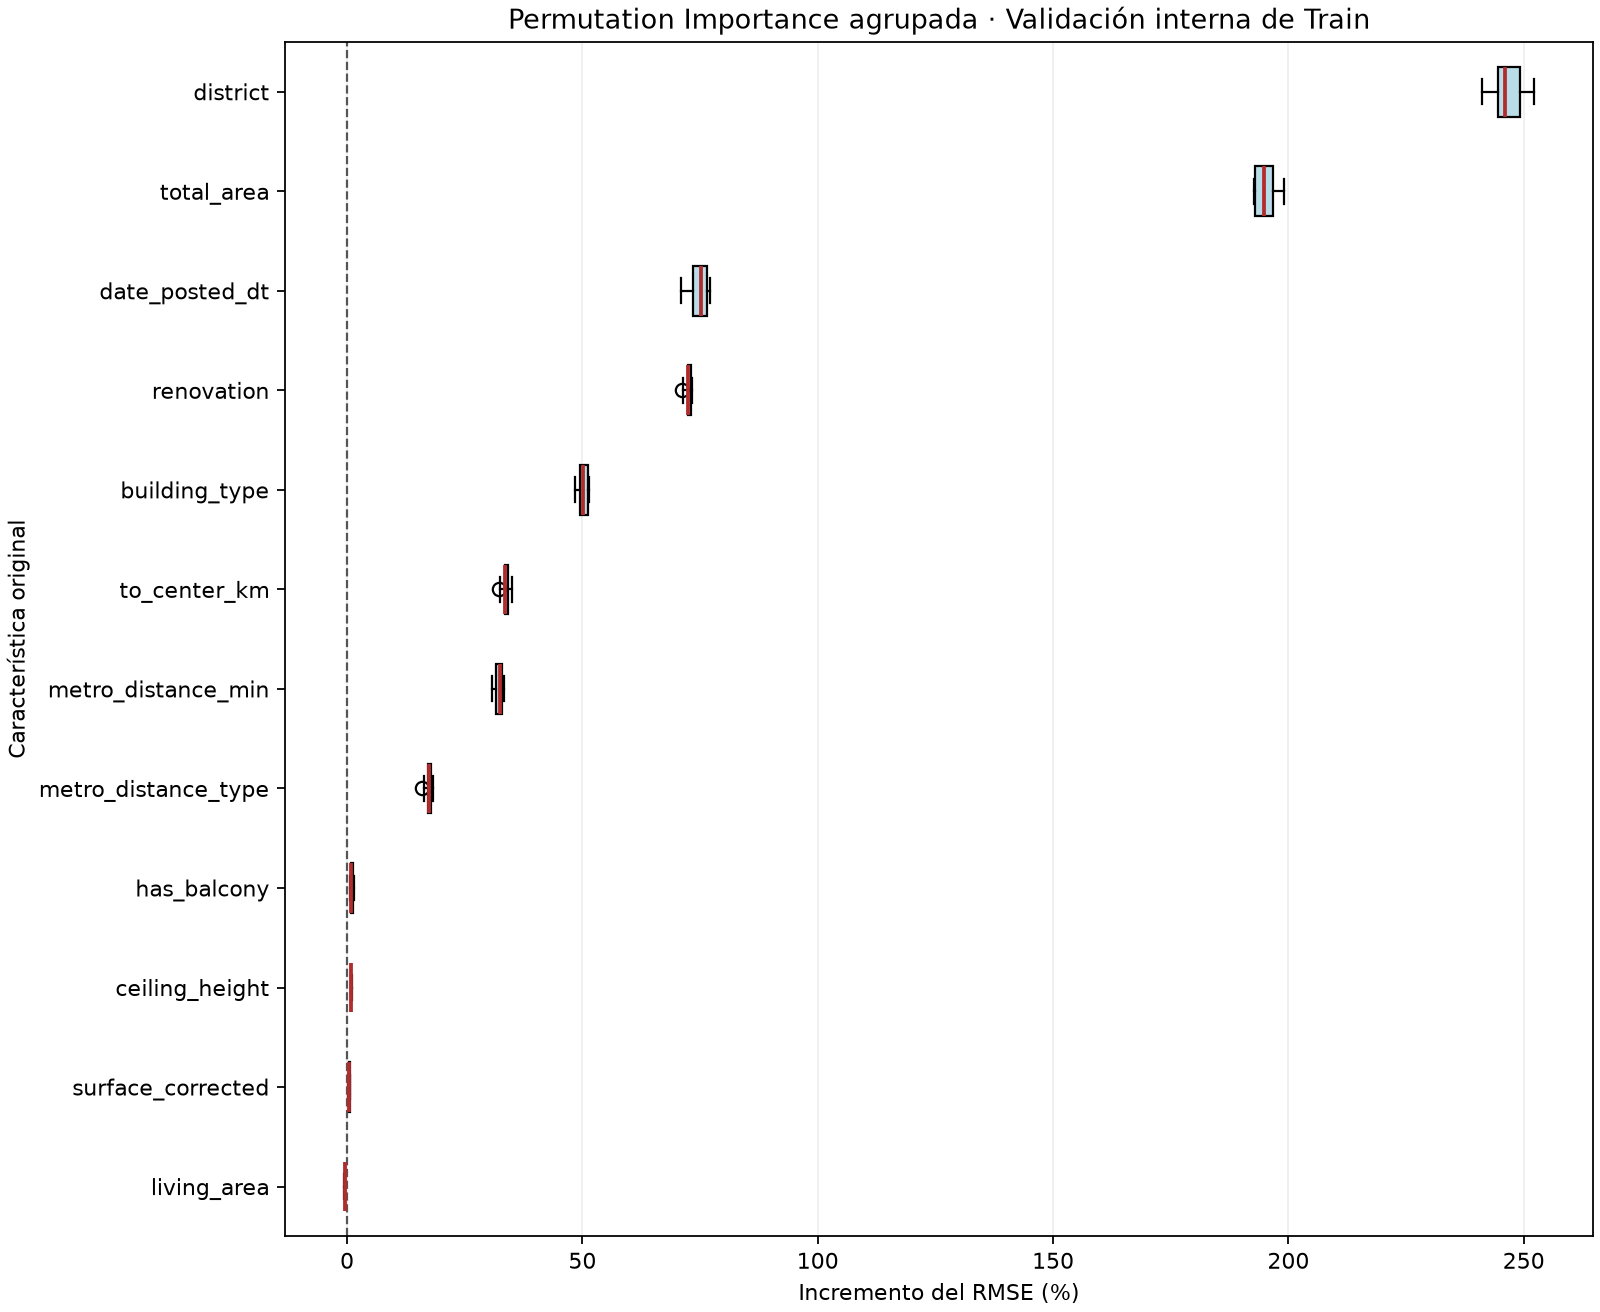

Mayores medianas de incremento del RMSE: `district` (246.1 %), `total_area` (194.8 %), `date_posted_dt` (75.2 %); 10 permutaciones por grupo.  
Las columnas de cada grupo se permutan conjuntamente respecto de price_rub; no mide efectos causales ni magnitudes de coeficientes OLS.  
Se reutiliza la validación de selección; correlaciones entre características pueden afectar la importancia.

In [32]:
display(Image(filename=str(lasso_177['salida'] / 'importancia_caracteristicas_boxplot.png')))
display(Markdown(s.interpretar_importancia(lasso_177)))


In [33]:
display(Markdown(s.confirmacion_presentacion(lasso_177)))


Recuperado de MLflow; sin nueva selección ni ajuste final · **FINISHED** · [GroupLasso_05_Log_177_Grupos_OLS](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/cda36a216ba1492eb1e87049344159c3)

### Comparación específica: universo inicial de 177 columnas
Forward, Group Lasso + OLS y Backward comparten candidatas, observaciones internas y escalas. Las características seleccionadas pueden diferir; los RMSE de selección no constituyen una evaluación independiente.


In [34]:
tabla_177, coincidencias_177, analisis_177 = s.comparacion_177_presentacion(forward_177, lasso_177, backward)
display(Markdown(tabla_177))
display(Markdown(coincidencias_177))
display(Markdown(analisis_177))


| Método | Características | Columnas OLS | R² ajustado Train [log] | RMSE Train (RUB) | RMSE interno (RUB) | AIC [log] | BIC [log] |
|---|---|---|---|---|---|---|---|
| Forward Selection | 8 | 141 | 0.953796 | 1,602,567.630 | 1,603,607.587 | -53,202.517 | -51,989.138 |
| Group Lasso + OLS | 12 | 145 | 0.954876 | 1,587,916.804 | 1,589,425.419 | -54,096.635 | -52,849.076 |
| Backward Selection | 12 | 145 | 0.955228 | 1,581,589.473 | 1,581,085.284 | -54,393.951 | -53,146.392 |

Comunes a los tres: `building_type`, `date_posted_dt`, `district`, `metro_distance_min`, `metro_distance_type`, `renovation`, `total_area`.  
Exclusivas de Forward Selection: Ninguna.  
Exclusivas de Group Lasso + OLS: `living_area`.  
Exclusivas de Backward Selection: Ninguna.  
Compartidas solo por Forward Selection y Group Lasso + OLS: Ninguna.  
Compartidas solo por Forward Selection y Backward Selection: `rooms`.  
Compartidas solo por Group Lasso + OLS y Backward Selection: `ceiling_height`, `has_balcony`, `surface_corrected`, `to_center_km`.

`to_center_km` — Forward — 177: no; Group Lasso + OLS — 177: sí; Backward — 177: sí.  
`living_area` — Forward — 177: no; Group Lasso + OLS — 177: sí; Backward — 177: no.  
`rooms` — Forward — 177: sí; Group Lasso + OLS — 177: no; Backward — 177: sí.  
Backward — 177 obtuvo el menor RMSE interno (1,581,085 RUB). El universo inicial de 177 columnas y la partición son compartidos. La validación participó en la selección; esta comparación no constituye una evaluación independiente sobre datos nuevos.

## 7. Comparación de características seleccionadas
Se recuperan exclusivamente `Forward_04_Log_177_Grupos`, `Backward_03_Log_177_Grupos_OLS` y `GroupLasso_05_Log_177_Grupos_OLS`. Cada fila corresponde a una característica original, con bloques One-Hot completos; las comunes a los tres se resaltan en negrita. La tabla, las coincidencias y la unión se calculan desde sus artefactos verificados, sin listas manuales ni una selección adicional por correlación, p-value o VIF.


In [35]:
with sesion.paso():
    datos_bss = datos_lasso_177
    cuadro_bss, universo_bss = bs.construir_universo(datos_bss, forward_177, backward, lasso_177)


In [36]:
cuadro_bss_md, resumen_union_bss = bs.cuadro_presentacion(cuadro_bss, universo_bss)
display(Markdown(cuadro_bss_md))
display(Markdown(resumen_union_bss))


| Característica original | Forward 177 | Backward 177 | Group Lasso 177 | Número de métodos | Clasificación de coincidencia |
|---|---|---|---|---|---|
| **`building_type`** | ✓ | ✓ | ✓ | 3 | Los 3 |
| **`date_posted_dt`** | ✓ | ✓ | ✓ | 3 | Los 3 |
| **`district`** | ✓ | ✓ | ✓ | 3 | Los 3 |
| **`metro_distance_min`** | ✓ | ✓ | ✓ | 3 | Los 3 |
| **`metro_distance_type`** | ✓ | ✓ | ✓ | 3 | Los 3 |
| **`renovation`** | ✓ | ✓ | ✓ | 3 | Los 3 |
| **`total_area`** | ✓ | ✓ | ✓ | 3 | Los 3 |
| `ceiling_height` | — | ✓ | ✓ | 2 | Backward 177 y Group Lasso 177 |
| `has_balcony` | — | ✓ | ✓ | 2 | Backward 177 y Group Lasso 177 |
| `rooms` | ✓ | ✓ | — | 2 | Forward 177 y Backward 177 |
| `surface_corrected` | — | ✓ | ✓ | 2 | Backward 177 y Group Lasso 177 |
| `to_center_km` | — | ✓ | ✓ | 2 | Backward 177 y Group Lasso 177 |
| `living_area` | — | — | ✓ | 1 | Solo Group Lasso 177 |

Forward 177: 8 características; Backward 177: 12 características; Group Lasso 177: 12 características. Coinciden en los tres: 7; en exactamente dos: 5; exclusivas: 1. Unión: 13 características / 146 columnas. Se incluyen todas las características elegidas por al menos un método, sin priorizar las comunes ni excluir las exclusivas. BSS estudia exhaustivamente esa unión, no solo la intersección.

## 8. Best Subset Selection
Búsqueda **exhaustiva agrupada** sobre la unión completa. M0 contiene solo intercepto. Para cada tamaño k se elige exclusivamente el subconjunto identificable con menor RSS del entrenamiento interno en `ln(price_rub)`; un empate exacto se resuelve por la primera combinación según el orden del linaje, sin consultar la validación.
Se evalúan todos los tamaños, incluido el máximo, aunque supere el límite final de 12. Solo después se comparan los ganadores por tamaño mediante RMSE interno en RUB (`exp`, sin corrección de sesgo), en complejidad creciente, aceptando mejoras ≥0,5 % frente al último aceptado, desde M0. Un rechazo no detiene tamaños posteriores. Sin candidato aceptable no se registra un ganador.
Se reutilizan los mismos índices internos 80/20, semilla 42. QR y productos matriciales aceleran OLS sin alterar el dataset ni omitir combinaciones; los RSS ganadores se contrastan con OLS directo. Los diseños de rango deficiente quedan registrados y no pueden ganar. El OLS definitivo se reajusta con todo Train sobre las escalas exportadas. Test no participa.
Run exclusivo: `BSS_06_Log_Union_177_Grupos_OLS`. `modo="nuevo"` exige un nombre libre; después del registro se utiliza recuperación estricta del dataset, universo, partición y los tres Runs de origen. El historial completo se conserva en MLflow, evitando imprimir miles de combinaciones.
**Limitación metodológica:** la unión fue construida por tres métodos que ya utilizaron la misma validación. Reutilizarla en BSS puede producir sesgo por selección y optimismo; los cuatro modelos constituyen una comparación exploratoria, no una evaluación independiente.


In [37]:
with sesion.paso():
    bss = bs.ejecutar_presentacion(datos_bss, universo_bss, modo="recuperar")


In [38]:
resumen_bss, coeficientes_bss = bss['caracteristicas_md'].split("\n\n", 1)
display(Markdown(resumen_bss + "\n\n<details><summary>Columnas transformadas y coeficientes OLS</summary>\n\n"
                 + coeficientes_bss + "\n\n</details>"))


| Característica seleccionada | Cantidad de predictores |
|---|---|
| `total_area` | 1 |
| `rooms` | 1 |
| `ceiling_height` | 1 |
| `metro_distance_min` | 1 |
| `to_center_km` | 1 |
| `surface_corrected` | 1 |
| `has_balcony` | 1 |
| `metro_distance_type` | 1 |
| `building_type` | 5 |
| `renovation` | 3 |
| `district` | 128 |
| `date_posted_dt` | 1 |
| Total: 12 características | 145 predictores |

<details><summary>Columnas transformadas y coeficientes OLS</summary>

| Característica original | Columna transformada | Coeficiente OLS [ln(RUB)] |
|---|---|---|
| total_area | total_area | 0.0158 |
| rooms | rooms | -0.0225 |
| ceiling_height | ceiling_height | 0.0456 |
| metro_distance_min | metro_distance_min | -0.0017 |
| to_center_km | to_center_km | -0.0078 |
| surface_corrected | surface_corrected | -0.1475 |
| has_balcony | has_balcony | 0.0309 |
| metro_distance_type | metro_distance_type | -0.1249 |
| building_type | building_type_khrushchev | -0.2102 |
| building_type | building_type_modern_panel | -0.0477 |
| building_type | building_type_monolith | 0.0454 |
| building_type | building_type_panel | -0.1322 |
| building_type | building_type_stalin | 0.1322 |
| renovation | renovation_designer | 0.3053 |
| renovation | renovation_euro | 0.1450 |
| renovation | renovation_no_renovation | -0.1110 |
| district | district_akademichesky | 0.1754 |
| district | district_alekseevsky | -0.0090 |
| district | district_altufyevsky | -0.2900 |
| district | district_arbat | 0.7328 |
| district | district_babushkinsky | -0.2064 |
| district | district_basmanny | 0.4852 |
| district | district_begovoy | 0.1387 |
| district | district_beskudnikovsky | -0.2679 |
| district | district_bibirevo | -0.2590 |
| district | district_biryulyovo_vostochnoye | -0.3662 |
| district | district_biryulyovo_zapadnoye | -0.3461 |
| district | district_bogorodskoye | -0.2132 |
| district | district_brateyevo | -0.3522 |
| district | district_butyrsky | -0.0668 |
| district | district_chertanovo_severnoye | -0.1933 |
| district | district_chertanovo_tsentralnoye | -0.2911 |
| district | district_chertanovo_yuzhnoye | -0.2024 |
| district | district_cheryomushki | 0.1799 |
| district | district_danilovsky | 0.0136 |
| district | district_desyonovskoye | -0.4765 |
| district | district_dmitrovsky | -0.3039 |
| district | district_donskoy | 0.0861 |
| district | district_dorogomilovo | 0.4668 |
| district | district_fili_davydkovo | 0.1820 |
| district | district_filimonkovskoye | -0.6095 |
| district | district_filyovsky_park | 0.2352 |
| district | district_gagarinsky | 0.3063 |
| district | district_golovinsky | -0.1959 |
| district | district_golyanovo | -0.2875 |
| district | district_ivanovskoye | -0.2787 |
| district | district_izmaylovo | -0.1124 |
| district | district_khamovniki | 0.7604 |
| district | district_khoroshyovo_mnyovniki | 0.1010 |
| district | district_khoroshyovsky | 0.1691 |
| district | district_khovrino | -0.2865 |
| district | district_kievsky | -0.5267 |
| district | district_klyonovskoye | -0.7022 |
| district | district_kokoshkino | -0.6138 |
| district | district_konkovo | 0.0240 |
| district | district_koptevo | -0.1861 |
| district | district_kosino_ukhtomsky | -0.3586 |
| district | district_kotlovka | 0.0692 |
| district | district_krasnopakhorskoye | -0.7580 |
| district | district_krasnoselsky | 0.4330 |
| district | district_krylatskoye | 0.2413 |
| district | district_kuntsevo | 0.0927 |
| district | district_kurkino | 0.0774 |
| district | district_levoberezhny | -0.1569 |
| district | district_lianozovo | -0.2879 |
| district | district_lomonosovsky | 0.3002 |
| district | district_losinoostrovsky | -0.2325 |
| district | district_marfino | -0.2210 |
| district | district_marushkinskoye | -0.6196 |
| district | district_maryina_roshcha | -0.0025 |
| district | district_meshchansky | 0.4762 |
| district | district_metrogorodok | -0.2752 |
| district | district_mikhaylovo_yartsevskoye | -0.7822 |
| district | district_mitino | -0.0607 |
| district | district_molzhaninovsky | -0.3541 |
| district | district_moskovsky | -0.4424 |
| district | district_moskvorechye_saburovo | -0.2254 |
| district | district_mosrentgen | -0.4054 |
| district | district_mozhaysky | 0.0164 |
| district | district_nagatino_sadovniki | -0.1233 |
| district | district_nagatinsky_zaton | -0.0938 |
| district | district_nagorny | -0.0607 |
| district | district_novo_peredelkino | -0.1646 |
| district | district_novofyodorovskoye | -0.5754 |
| district | district_novogireyevo | -0.1862 |
| district | district_novokosino | -0.2572 |
| district | district_obruchevsky | 0.1184 |
| district | district_ochakovo_matveyevskoye | 0.0111 |
| district | district_orekhovo_borisovo_severnoye | -0.3389 |
| district | district_orekhovo_borisovo_yuzhnoye | -0.3402 |
| district | district_ostankinsky | -0.0170 |
| district | district_otradnoye | -0.2159 |
| district | district_perovo | -0.0932 |
| district | district_pervomayskoye | -0.7127 |
| district | district_pokrovskoye_streshnevo | 0.0017 |
| district | district_preobrazhenskoye | -0.0413 |
| district | district_presnensky | 0.6805 |
| district | district_prospekt_vernadskogo | 0.3079 |
| district | district_ramenki | 0.3121 |
| district | district_rogovskoye | -0.5616 |
| district | district_rostokino | -0.2133 |
| district | district_ryazanovskoye | -0.5636 |
| district | district_savyolovsky | 0.0691 |
| district | district_severnoye_butovo | -0.1195 |
| district | district_severnoye_izmaylovo | -0.1517 |
| district | district_severnoye_medvedkovo | -0.2212 |
| district | district_severnoye_tushino | -0.1112 |
| district | district_severny | -0.3491 |
| district | district_shchapovskoye | -0.8357 |
| district | district_shcherbinka | -0.4657 |
| district | district_shchukino | 0.1878 |
| district | district_sokol | 0.1521 |
| district | district_sokolinaya_gora | -0.2184 |
| district | district_sokolniki | 0.0200 |
| district | district_solntsevo | -0.1093 |
| district | district_sosenskoye | -0.4350 |
| district | district_strogino | 0.2742 |
| district | district_sviblovo | -0.1775 |
| district | district_tagansky | 0.4445 |
| district | district_timiryazevsky | -0.0318 |
| district | district_troitsk | -0.6331 |
| district | district_troparyovo_nikulino | 0.2422 |
| district | district_tsaritsyno | -0.3001 |
| district | district_tverskoy | 0.7221 |
| district | district_tyoply_stan | -0.0312 |
| district | district_veshnyaki | -0.3671 |
| district | district_vnukovo | -0.1642 |
| district | district_vnukovskoye | -0.4366 |
| district | district_voronovskoye | -0.6237 |
| district | district_voskresenskoye | -0.5224 |
| district | district_vostochnoye_izmaylovo | -0.2178 |
| district | district_vostochny | -0.3772 |
| district | district_voykovsky | -0.0633 |
| district | district_yakimanka | 0.6752 |
| district | district_yaroslavsky | -0.2539 |
| district | district_yasenevo | 0.1463 |
| district | district_yuzhnoye_butovo | -0.1467 |
| district | district_yuzhnoye_medvedkovo | -0.2607 |
| district | district_yuzhnoye_tushino | -0.0547 |
| district | district_zamoskvorechye | 0.5589 |
| district | district_zapadnoye_degunino | -0.2978 |
| district | district_zelenograd | -0.4443 |
| district | district_zyablikovo | -0.3275 |
| district | district_zyuzino | 0.0295 |
| date_posted_dt | months_since_start | 0.0073 |

</details>

| k | Columnas | RSS interno [log]² | R² ajustado interno [log] | AIC interno [log] | BIC interno [log] | RMSE validación (RUB) |
|---|---|---|---|---|---|---|
| 0 | 0 | 9,423.514 | 0 | 50,659.262 | 50,667.583 | 6,073,206.112 |
| 1 | 128 | 3,494.911 | 0.627560 | 20,774.395 | 21,847.904 | 4,006,722.075 |
| 2 | 129 | 1,779.644 | 0.810343 | 268.372 | 1,350.202 | 3,072,722.644 |
| 3 | 130 | 1,301.431 | 0.861302 | -9,239.210 | -8,149.058 | 2,725,976.989 |
| 4 | 133 | 854.308 | 0.908944 | -22,023.953 | -20,908.835 | 2,296,175.987 |
| 5 | 138 | 545.988 | 0.941797 | -35,618.045 | -34,461.319 | 1,890,591.402 |
| 6 | 139 | 467.577 | 0.950154 | -40,327.061 | -39,162.013 | 1,713,611.937 |
| 7 | 140 | 437.995 | 0.953306 | -42,311.044 | -41,137.674 | 1,612,615.151 |
| 8 | 141 | 432.759 | 0.953863 | -42,674.438 | -41,492.746 | 1,606,387.596 |
| 9 | 142 | 428.541 | 0.954311 | -42,970.111 | -41,780.098 | 1,601,900.854 |
| 10 | 143 | 425.392 | 0.954645 | -43,192.222 | -41,993.887 | 1,593,555.592 |
| 11 | 144 | 422.369 | 0.954966 | -43,406.905 | -42,200.248 | 1,588,590.054 |
| 12 | 145 | 420.327 | 0.955182 | -43,552.180 | -42,337.201 | 1,581,085.284 |
| 13 | 146 | 420.297 | 0.955184 | -43,552.383 | -42,329.083 | 1,581,216.979 |

| Criterio | k favorecido | Valor | Tamaño elegible (1–12) |
|---|---|---|---|
| rss_train_log | 13 | 420.297 | False |
| r2_adj_train_log | 13 | 0.955184 | False |
| aic_train_log | 13 | -43,552.383 | False |
| bic_train_log | 12 | -42,337.201 | True |
| rmse_validation_original | 12 | 1,581,085.284 | True |
| Decisión principal: RMSE y mejora ≥0,5 % | 12 | 1,581,085.284 | True |

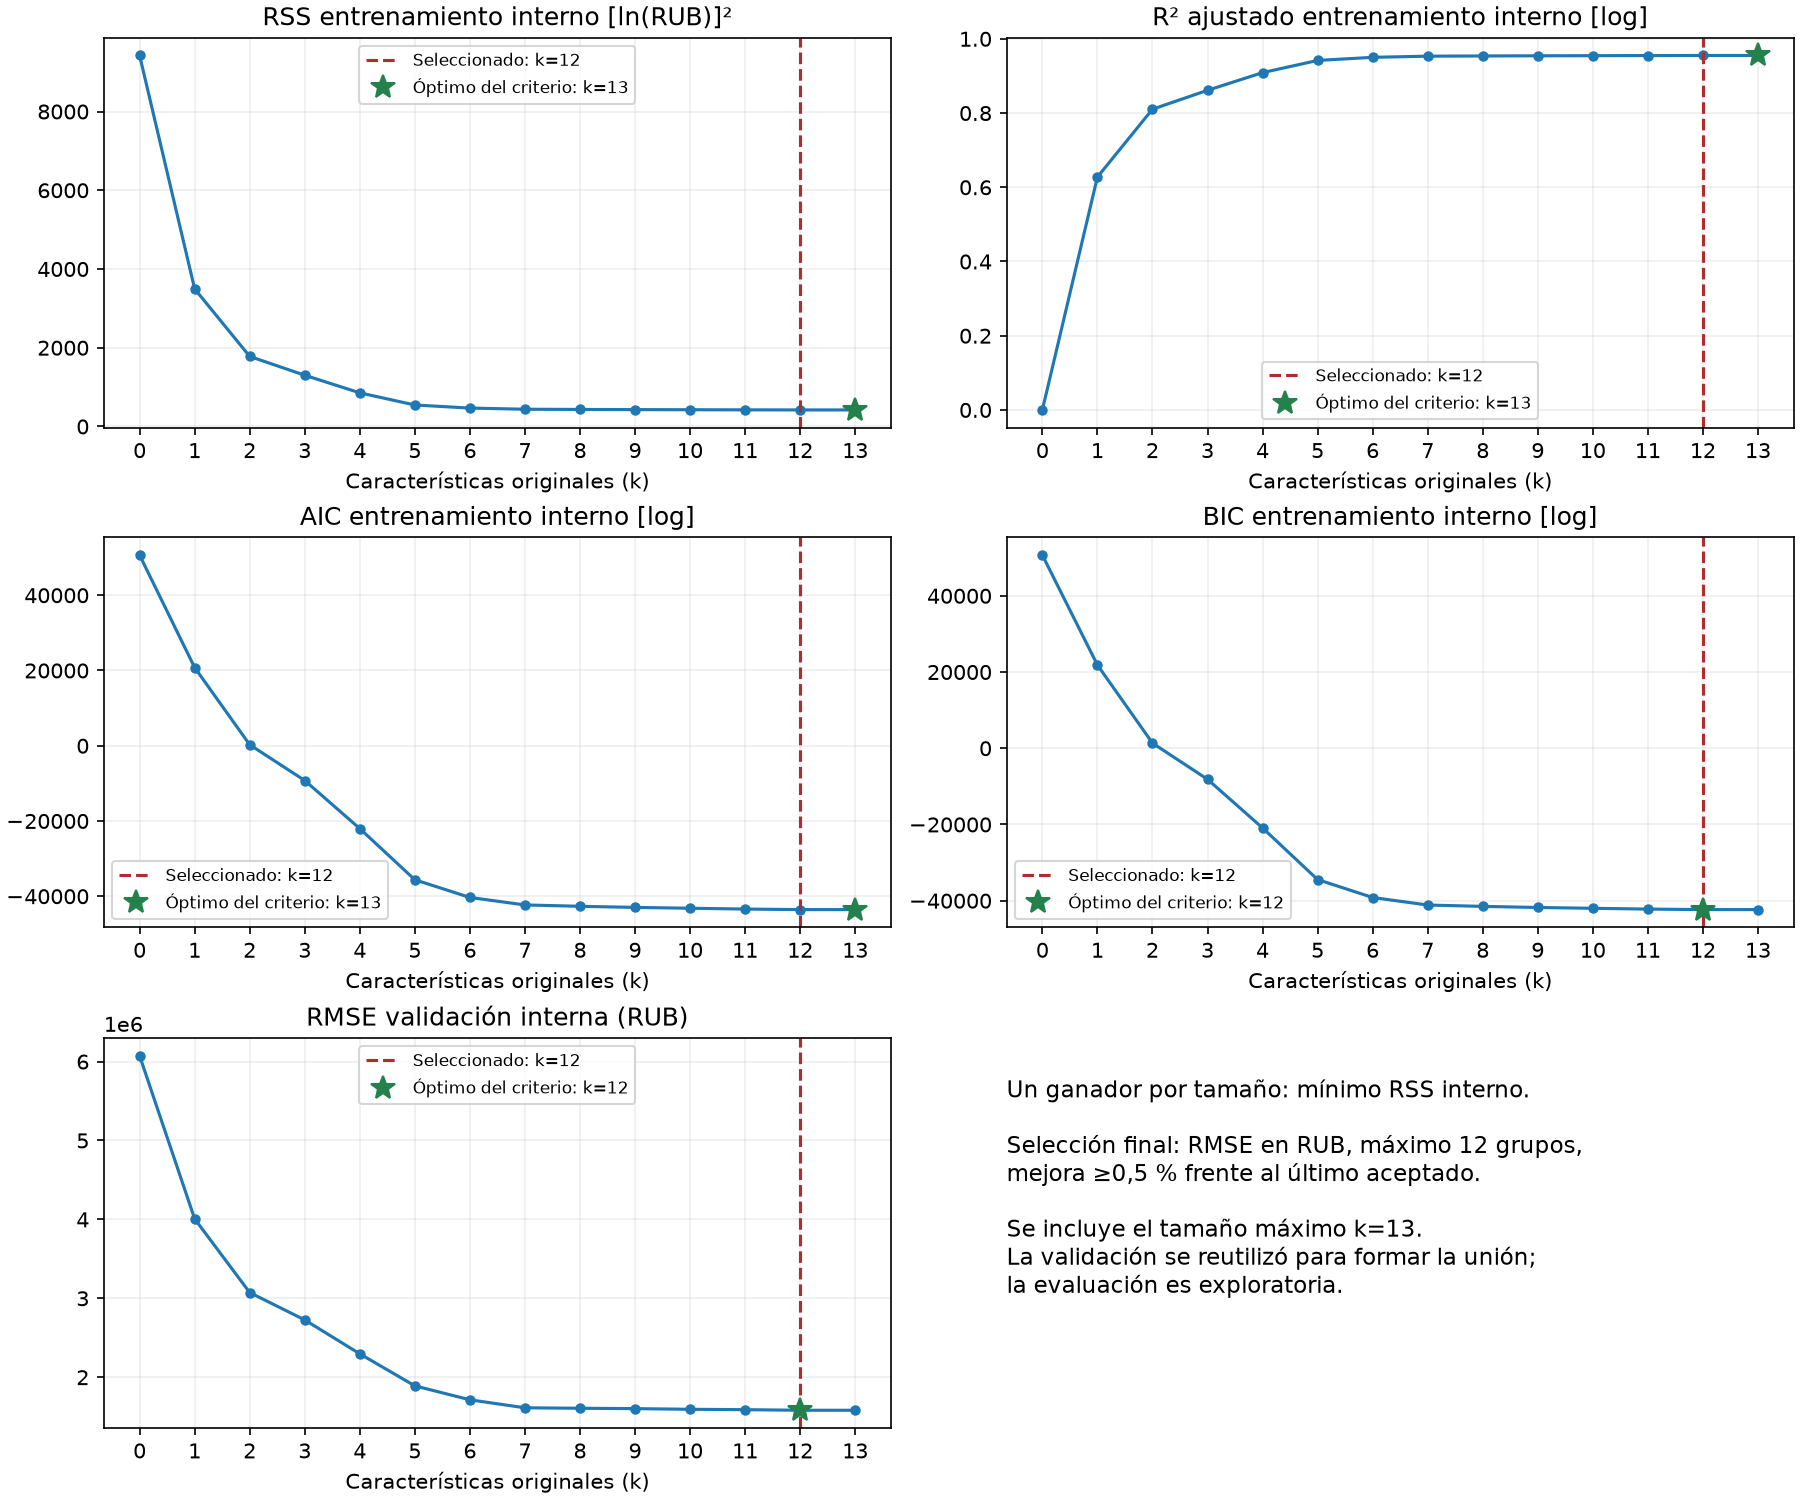

In [39]:
display(Markdown(bs.evolucion_presentacion(bss)))
display(Markdown(bs.criterios_presentacion(bss['seleccion'])))
display(Image(filename=str(bss['salida'] / 'evolucion_bss.png')))


In [40]:
display(Markdown(s.tabla_metricas_presentacion(bss)))


| Evaluación | Métrica | Best Subset Selection |
|---|---|---|
| Train | R² [ln(RUB)] | 0.955399 |
| Train | R² ajustado [ln(RUB)] | 0.955228 |
| Train | MAE (RUB) | 1,096,985.003 |
| Train | RMSE (RUB) | 1,581,589.473 |
| Train | AIC [ln(RUB)] | -54,393.951 |
| Train | BIC [ln(RUB)] | -53,146.392 |
| Train | VIF máximo | 102.537 |
| Train | Número de condición | 17,434.006 |
| Train | Breusch–Pagan (p) | 3.724e-117 |
| Train | Jarque–Bera (p) | 1.253e-42 |
| Validación interna | RMSE (RUB) | 1,581,085.284 |

In [41]:
display(Markdown(bs.interpretar_bss(bss)))


Se evaluaron 8,192/8,192 combinaciones (incluido M0), 8,192 identificables, sobre 13 grupos / 146 columnas. Solo 14 ganadores por RSS se compararon en validación. Elegido: 12 grupos. Excluidas de la unión: living_area. Óptimos alternativos entre mejores por tamaño (incluye M0 y el tamaño máximo): AIC: k=13; BIC: k=12; R² ajustado: k=13. Los criterios de evolución corresponden al entrenamiento interno; la tabla de métricas del OLS definitivo corresponde a todo Train. Máxima discrepancia RSS optimizado/OLS directo: 1.14e-11.

El OLS utiliza 12 características originales y 145 columnas predictoras, más el intercepto.  
R² ajustado log=0.95523; RMSE Train=1,581,589 RUB y validación interna=1,581,085 RUB.  
Persisten límites de homocedasticidad (BP p=3.72e-117) y normalidad (JB p=1.25e-42).  
La validación se utilizó para seleccionar: sus métricas no son una evaluación independiente. exp sin corrección puede sesgar el precio esperado.

La unión se construyó con métodos que ya utilizaron esta validación. BSS reutiliza información que influyó en sus candidatas: existe riesgo de sesgo por selección y optimismo. La comparación es exploratoria, no una evaluación independiente sobre datos nuevos. Test queda reservado para la evaluación final, una vez cerradas las decisiones metodológicas.

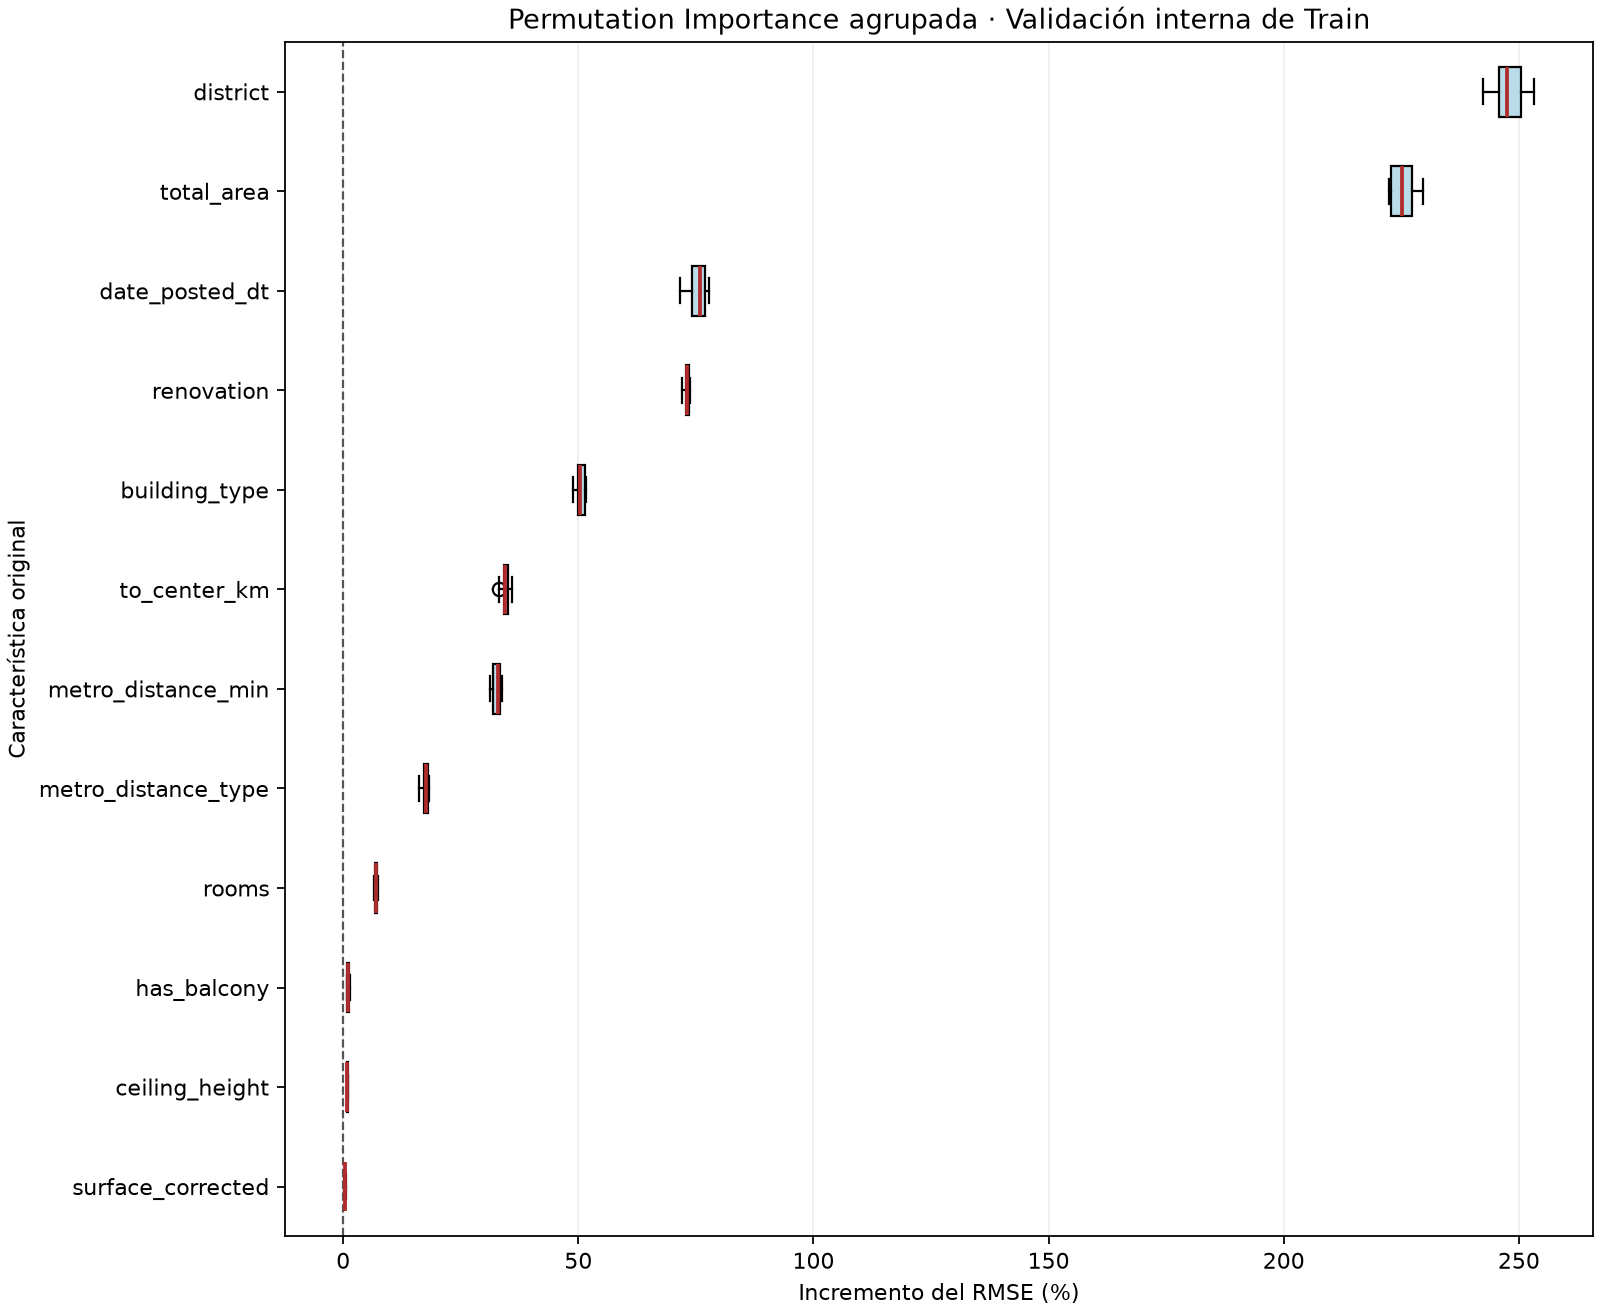

Mayores medianas de incremento del RMSE: `district` (247.4 %), `total_area` (225.2 %), `date_posted_dt` (75.9 %); 10 permutaciones por grupo.  
Las columnas de cada grupo se permutan conjuntamente respecto de price_rub; no mide efectos causales ni magnitudes de coeficientes OLS.  
Se reutiliza la validación de selección; correlaciones entre características pueden afectar la importancia.

In [42]:
display(Image(filename=str(bss['salida'] / 'importancia_caracteristicas_boxplot.png')))
display(Markdown(s.interpretar_importancia(bss)))


In [43]:
display(Markdown(s.confirmacion_presentacion(bss)))


Recuperado de MLflow; sin nueva selección ni ajuste final · **FINISHED** · [BSS_06_Log_Union_177_Grupos_OLS](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/9aee5b7348954fc48bf14562b6987e51)

### Comparación de Forward, Backward, Group Lasso y BSS
Los tres primeros partieron de 177 columnas. BSS parte de la unión derivada de sus selecciones; no tuvo exactamente el mismo universo candidato. Las métricas finales se calculan sobre las mismas filas y escalas. Se analiza el compromiso entre error, complejidad e interpretabilidad sin suponer superioridad por explorar más combinaciones.


In [44]:
tabla_bss_177, analisis_bss_177 = bs.comparar_177(forward_177, backward, lasso_177, bss)
display(Markdown(tabla_bss_177))
display(Markdown(analisis_bss_177))


| Método | Características candidatas | Columnas candidatas | Características seleccionadas | Columnas OLS | R² ajustado Train [log] | RMSE Train (RUB) | RMSE interno (RUB) | AIC [log] | BIC [log] |
|---|---|---|---|---|---|---|---|---|---|
| Forward 177 | 23 | 177 | 8 | 141 | 0.953796 | 1,602,567.630 | 1,603,607.587 | -53,202.517 | -51,989.138 |
| Backward 177 | 23 | 177 | 12 | 145 | 0.955228 | 1,581,589.473 | 1,581,085.284 | -54,393.951 | -53,146.392 |
| Group Lasso 177 | 23 | 177 | 12 | 145 | 0.954876 | 1,587,916.804 | 1,589,425.419 | -54,096.635 | -52,849.076 |
| BSS unión | 13 | 146 | 12 | 145 | 0.955228 | 1,581,589.473 | 1,581,085.284 | -54,393.951 | -53,146.392 |

Comunes a los tres orígenes conservadas por BSS: `building_type`, `date_posted_dt`, `district`, `metro_distance_min`, `metro_distance_type`, `renovation`, `total_area`.  
Comunes descartadas por BSS: ninguna.  
Compartidas por exactamente dos que BSS conservó: `ceiling_height`, `has_balcony`, `rooms`, `surface_corrected`, `to_center_km`.  
Exclusivas de un origen que BSS conservó: ninguna.  
BSS frente a Forward 177: comparte `building_type`, `date_posted_dt`, `district`, `metro_distance_min`, `metro_distance_type`, `renovation`, `rooms`, `total_area`; añade `ceiling_height`, `has_balcony`, `surface_corrected`, `to_center_km`; omite ninguna.  
BSS frente a Backward 177: comparte `building_type`, `ceiling_height`, `date_posted_dt`, `district`, `has_balcony`, `metro_distance_min`, `metro_distance_type`, `renovation`, `rooms`, `surface_corrected`, `to_center_km`, `total_area`; añade ninguna; omite ninguna.  
BSS frente a Group Lasso 177: comparte `building_type`, `ceiling_height`, `date_posted_dt`, `district`, `has_balcony`, `metro_distance_min`, `metro_distance_type`, `renovation`, `surface_corrected`, `to_center_km`, `total_area`; añade `rooms`; omite `living_area`.  
Menor RMSE interno: Backward 177, BSS unión (1,581,085 RUB). Equilibrio descriptivo entre error y parsimonia: Backward 177, BSS unión, el modelo más compacto entre los que quedan a ≤0,5 % del menor RMSE. Esta regla describe el compromiso; no reemplaza la selección BSS.  
Los tres orígenes partieron de 177 columnas; BSS parte de su unión de 13 grupos / 146 columnas. Los cuatro universos candidatos no son idénticos. Examinar más combinaciones no garantiza superioridad.  
La unión se construyó con métodos que ya utilizaron esta validación. BSS reutiliza información que influyó en sus candidatas: existe riesgo de sesgo por selección y optimismo. La comparación es exploratoria, no una evaluación independiente sobre datos nuevos. Test queda reservado para la evaluación final, una vez cerradas las decisiones metodológicas.

## 9. Validación cruzada temporal — BSS
Se utilizan **3 folds expansivos** sobre Train cronológico, manteniendo fijos los 13 grupos candidatos y reservando Test.
BSS minimiza el RSS de cada entrenamiento por tamaño; los RMSE temporales (RUB) se agregan para elegir el modelo mediante **1-SE**.


In [47]:
from scripts import bss_temporal as bt
with SesionTemporal() as sesion_cv:
    temporal_bss = bt.ejecutar_presentacion(base, sesion_cv, datos['cliente'], modo="recuperar")


In [48]:
display(Markdown(bt.tabla_presentacion(temporal_bss)))


| Características | RMSE Fold 1 | RMSE Fold 2 | RMSE Fold 3 | RMSE promedio | Error estándar |
|---|---|---|---|---|---|
| 1 | 5,568,485 | 6,242,513 | 6,755,328 | 6,188,775 | 343,664 |
| 2 | 4,084,100 | 4,570,029 | 5,003,412 | 4,552,514 | 265,527 |
| 3 | 3,670,009 | 4,036,990 | 4,446,553 | 4,051,184 | 224,281 |
| 4 | 3,315,604 | 3,623,831 | 3,492,682 | 3,477,373 | 89,306 |
| 5 | 2,239,775 | 2,716,277 | 3,047,991 | 2,668,014 | 234,556 |
| **6** | **2,067,676** | **2,569,269** | **2,803,632** | **2,480,192** | **217,071** |
| 7 | 1,946,372 | 2,433,713 | 2,680,145 | 2,353,410 | 215,594 |
| 8 | 1,951,030 | 2,437,391 | 2,670,901 | 2,353,108 | 212,039 |
| 9 | 1,940,030 | 2,430,981 | 2,659,076 | 2,343,362 | 212,143 |
| 10 | 1,942,350 | 2,421,493 | 2,653,211 | 2,339,018 | 209,310 |
| 11 | 1,936,733 | 2,415,275 | 2,637,144 | 2,329,717 | 206,667 |
| 12 | 1,931,472 | 2,412,293 | 2,630,785 | 2,324,850 | 206,554 |

In [49]:
display(Markdown(bt.modelo_presentacion(temporal_bss)))
display(Markdown(bt.detalles_presentacion(temporal_bss)))


Menor RMSE promedio: **12 características**. Regla 1-SE: **6 características**, RMSE temporal promedio **2,480,192 RUB**. OLS definitivo: `total_area`, `metro_distance_type`, `building_type`, `renovation`, `district`, `date_posted_dt`; **139 columnas transformadas**, más intercepto.

<details><summary>Detalles técnicos y limitaciones (cerrado por defecto)</summary>

La unión y el vocabulario OHE están fijados por el BSS previo, construido con todo Train: esta CV es condicional a esa selección y no es una evaluación independiente. Se utiliza Train crudo anterior a Test, sin el filtro Tukey global del dataset histórico; por ello las filas y los errores no son directamente comparables con los históricos. Imputación y origen temporal se ajustan únicamente en el pasado de cada fold. El esquema OHE heredado es fijo; no se aprenden categorías con la validación. Con tres folds expansivos correlacionados, 1-SE es una regla práctica de parsimonia, no una garantía estadística de superioridad. Test no se utiliza.

MLflow: [BSS_07_Log_Temporal_3F_1SE_OLS](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/4b3e5cf9cac24ccdbda3d3568e3fb0a5) · **FINISHED** · recuperar. Train: 39,998 publicaciones.

```json
{
  "configuracion": {
    "version": "temporal_bss_minimal_1se_v1",
    "algorithm": {
      "n_folds": 3,
      "max_features": 12,
      "rule": "one_standard_error",
      "target": "ln(price_rub)",
      "inverse": "exp",
      "bias_correction": "none"
    },
    "identity": {
      "train_sha256": "3ac0fa51111c46b1587c0221e33a9592fd700e32cfe586be428279f58892d98f",
      "n_train": 39998,
      "train_end": "2025-01-16",
      "raw_file_sha256": "e6f20c2be10600c34822faff007742e4a9965b7f3492b00d8612ea1aadb40491",
      "source": "chronological raw Train; no global Tukey filtering",
      "test_used": false
    },
    "source_bss_run_id": "9aee5b7348954fc48bf14562b6987e51",
    "groups": {
      "total_area": [
        "total_area"
      ],
      "living_area": [
        "living_area"
      ],
      "rooms": [
        "rooms"
      ],
      "ceiling_height": [
        "ceiling_height"
      ],
      "metro_distance_min": [
        "metro_distance_min"
      ],
      "to_center_km": [
        "to_center_km"
      ],
      "surface_corrected": [
        "surface_corrected"
      ],
      "has_balcony": [
        "has_balcony"
      ],
      "metro_distance_type": [
        "metro_distance_type"
      ],
      "building_type": [
        "building_type_khrushchev",
        "building_type_modern_panel",
        "building_type_monolith",
        "building_type_panel",
        "building_type_stalin"
      ],
      "renovation": [
        "renovation_designer",
        "renovation_euro",
        "renovation_no_renovation"
      ],
      "district": [
        "district_akademichesky",
        "district_alekseevsky",
        "district_altufyevsky",
        "district_arbat",
        "district_babushkinsky",
        "district_basmanny",
        "district_begovoy",
        "district_beskudnikovsky",
        "district_bibirevo",
        "district_biryulyovo_vostochnoye",
        "district_biryulyovo_zapadnoye",
        "district_bogorodskoye",
        "district_brateyevo",
        "district_butyrsky",
        "district_chertanovo_severnoye",
        "district_chertanovo_tsentralnoye",
        "district_chertanovo_yuzhnoye",
        "district_cheryomushki",
        "district_danilovsky",
        "district_desyonovskoye",
        "district_dmitrovsky",
        "district_donskoy",
        "district_dorogomilovo",
        "district_fili_davydkovo",
        "district_filimonkovskoye",
        "district_filyovsky_park",
        "district_gagarinsky",
        "district_golovinsky",
        "district_golyanovo",
        "district_ivanovskoye",
        "district_izmaylovo",
        "district_khamovniki",
        "district_khoroshyovo_mnyovniki",
        "district_khoroshyovsky",
        "district_khovrino",
        "district_kievsky",
        "district_klyonovskoye",
        "district_kokoshkino",
        "district_konkovo",
        "district_koptevo",
        "district_kosino_ukhtomsky",
        "district_kotlovka",
        "district_krasnopakhorskoye",
        "district_krasnoselsky",
        "district_krylatskoye",
        "district_kuntsevo",
        "district_kurkino",
        "district_levoberezhny",
        "district_lianozovo",
        "district_lomonosovsky",
        "district_losinoostrovsky",
        "district_marfino",
        "district_marushkinskoye",
        "district_maryina_roshcha",
        "district_meshchansky",
        "district_metrogorodok",
        "district_mikhaylovo_yartsevskoye",
        "district_mitino",
        "district_molzhaninovsky",
        "district_moskovsky",
        "district_moskvorechye_saburovo",
        "district_mosrentgen",
        "district_mozhaysky",
        "district_nagatino_sadovniki",
        "district_nagatinsky_zaton",
        "district_nagorny",
        "district_novo_peredelkino",
        "district_novofyodorovskoye",
        "district_novogireyevo",
        "district_novokosino",
        "district_obruchevsky",
        "district_ochakovo_matveyevskoye",
        "district_orekhovo_borisovo_severnoye",
        "district_orekhovo_borisovo_yuzhnoye",
        "district_ostankinsky",
        "district_otradnoye",
        "district_perovo",
        "district_pervomayskoye",
        "district_pokrovskoye_streshnevo",
        "district_preobrazhenskoye",
        "district_presnensky",
        "district_prospekt_vernadskogo",
        "district_ramenki",
        "district_rogovskoye",
        "district_rostokino",
        "district_ryazanovskoye",
        "district_savyolovsky",
        "district_severnoye_butovo",
        "district_severnoye_izmaylovo",
        "district_severnoye_medvedkovo",
        "district_severnoye_tushino",
        "district_severny",
        "district_shchapovskoye",
        "district_shcherbinka",
        "district_shchukino",
        "district_sokol",
        "district_sokolinaya_gora",
        "district_sokolniki",
        "district_solntsevo",
        "district_sosenskoye",
        "district_strogino",
        "district_sviblovo",
        "district_tagansky",
        "district_timiryazevsky",
        "district_troitsk",
        "district_troparyovo_nikulino",
        "district_tsaritsyno",
        "district_tverskoy",
        "district_tyoply_stan",
        "district_veshnyaki",
        "district_vnukovo",
        "district_vnukovskoye",
        "district_voronovskoye",
        "district_voskresenskoye",
        "district_vostochnoye_izmaylovo",
        "district_vostochny",
        "district_voykovsky",
        "district_yakimanka",
        "district_yaroslavsky",
        "district_yasenevo",
        "district_yuzhnoye_butovo",
        "district_yuzhnoye_medvedkovo",
        "district_yuzhnoye_tushino",
        "district_zamoskvorechye",
        "district_zapadnoye_degunino",
        "district_zelenograd",
        "district_zyablikovo",
        "district_zyuzino"
      ],
      "date_posted_dt": [
        "months_since_start"
      ]
    },
    "folds": [
      {
        "fold": 1,
        "fit_start": 0,
        "fit_stop": 9993,
        "val_start": 9993,
        "val_stop": 19995,
        "fit_from": "2020-01-01",
        "fit_until": "2021-04-07",
        "val_from": "2021-04-08",
        "val_until": "2022-07-15"
      },
      {
        "fold": 2,
        "fit_start": 0,
        "fit_stop": 19995,
        "val_start": 19995,
        "val_stop": 30010,
        "fit_from": "2020-01-01",
        "fit_until": "2022-07-15",
        "val_from": "2022-07-16",
        "val_until": "2023-10-14"
      },
      {
        "fold": 3,
        "fit_start": 0,
        "fit_stop": 30010,
        "val_start": 30010,
        "val_stop": 39998,
        "fit_from": "2020-01-01",
        "fit_until": "2023-10-14",
        "val_from": "2023-10-15",
        "val_until": "2025-01-16"
      }
    ],
    "limitations": "La unión y el vocabulario OHE están fijados por el BSS previo, construido con todo Train: esta CV es condicional a esa selección y no es una evaluación independiente. Se utiliza Train crudo anterior a Test, sin el filtro Tukey global del dataset histórico; por ello las filas y los errores no son directamente comparables con los históricos. Imputación y origen temporal se ajustan únicamente en el pasado de cada fold. El esquema OHE heredado es fijo; no se aprenden categorías con la validación. Con tres folds expansivos correlacionados, 1-SE es una regla práctica de parsimonia, no una garantía estadística de superioridad. Test no se utiliza.",
    "preprocessing": "prefix-only imputation; frozen OHE schema; prefix month origin; no global Tukey/scaler",
    "versions": {
      "numpy": "2.5.4",
      "pandas": "3.0.6",
      "scipy": "1.18.1",
      "statsmodels": "0.15.0",
      "scikit-learn": "1.9.1",
      "joblib": "1.6.0"
    },
    "code_sha256": {
      "bss_temporal.py": "d946938f30ff0ddd0e3872b8c31289645841e3a8377f676cfa93635197752dff",
      "bss_ols.py": "7e8e34cc29e5991e5fab613345670b3c930313e41135186ffaf03f023aae19b6",
      "preparacion_train_test.py": "77538a434c24ded719044d083ecedb186d6ed86fc416a79caa49d85e17a349e9"
    }
  },
  "comprobaciones": [
    {
      "evaluados": 8190,
      "no_identificables": 0,
      "rango_union": 147,
      "preprocessor_fit_rows": 9993,
      "preprocessor_fit_until": "2021-04-07"
    },
    {
      "evaluados": 8190,
      "no_identificables": 0,
      "rango_union": 147,
      "preprocessor_fit_rows": 19995,
      "preprocessor_fit_until": "2022-07-15"
    },
    {
      "evaluados": 8190,
      "no_identificables": 0,
      "rango_union": 147,
      "preprocessor_fit_rows": 30010,
      "preprocessor_fit_until": "2023-10-14"
    }
  ],
  "comprobacion_final": {
    "evaluados": 1716,
    "no_identificables": 0,
    "rango_union": 147
  },
  "regla": {
    "k_min": 12,
    "k_selected": 6,
    "threshold": 2531404.4535527388,
    "selected_mean": 2480192.274808777,
    "se_at_minimum": 206554.33828924113
  }
}
```

</details>

## 10. Comparación final

### ¿Qué características seleccionó cada modelo?

La matriz muestra las características originales de la unión utilizada por BSS. La última columna identifica el **modelo final elegido mediante validación temporal y regla 1-SE**. Las selecciones y métricas se leen de los resultados recuperados en las secciones anteriores; no se vuelve a ajustar ningún modelo.

In [ ]:
from scripts import presentacion_final as pf
from IPython.display import HTML
datos_finales = pf.preparar(forward_177, backward, lasso_177, bss, temporal_bss)
display(HTML(pf.matriz_html(datos_finales)))
display(Markdown(pf.observaciones(datos_finales)))

Característica original,Forward Selection177,Backward Selection177,Group Lasso + OLS177,BSShistórico,BSS temporalmodelo final
building_type,✓,✓,✓,✓,✓
date_posted_dt,✓,✓,✓,✓,✓
district,✓,✓,✓,✓,✓
metro_distance_min,✓,✓,✓,✓,—
metro_distance_type,✓,✓,✓,✓,✓
renovation,✓,✓,✓,✓,✓
total_area,✓,✓,✓,✓,✓
rooms,✓,✓,—,✓,—
ceiling_height,—,✓,✓,✓,—
has_balcony,—,✓,✓,✓,—


- Forward Selection — 177 fue el método más selectivo entre los tres algoritmos originales (8 características).
- Backward y BSS histórico terminaron con exactamente las mismas 12 características.
- La validación temporal redujo la selección final a 6 características originales.

### Recorrido histórico y decisión temporal

Las métricas históricas describen la validación interna de selección. Los resultados temporales se presentan por separado porque utilizan otro procesamiento de Train y tres folds cronológicos.

In [ ]:
display(Markdown("**Selección histórica — validación interna (RUB)**"))
display(Markdown(pf.tabla_historica(datos_finales)))
display(Markdown("**BSS temporal — tres folds cronológicos (RUB)**"))
display(Markdown(pf.tabla_temporal(datos_finales)))
display(Markdown(pf.interpretar_comparaciones(datos_finales)))

**Selección histórica — validación interna (RUB)**

| Modelo | Características finales | Columnas OLS | RMSE interno (RUB) |
|---|---|---|---|
| Forward Selection — 177 | 8 | 141 | 1.603.608 |
| Backward Selection — 177 | 12 | 145 | 1.581.085 |
| Group Lasso + OLS — 177 | 12 | 145 | 1.589.425 |
| BSS histórico | 12 | 145 | 1.581.085 |

**BSS temporal — tres folds cronológicos (RUB)**

| Criterio temporal | Características | RMSE promedio temporal (RUB) |
|---|---|---|
| Menor RMSE | 12 | 2.324.850 |
| **Regla 1-SE — elegido** | **6** | **2.480.192** |

BSS histórico alcanzó el mismo resultado que Backward. Para el criterio y el universo considerados, la búsqueda exhaustiva no mejoró el subconjunto obtenido mediante eliminación progresiva. Los RMSE históricos provienen de la validación interna utilizada en la selección y no de Test.

El BSS temporal utilizó tres folds cronológicos y Train crudo, con preparación dentro de cada ventana. Las dos tablas corresponden a poblaciones y procedimientos de evaluación diferentes: sus RMSE no son directamente comparables. La primera resume el recorrido histórico; la segunda fundamenta la complejidad del modelo definitivo.

### Modelo final seleccionado: BSS + validación cruzada temporal

In [ ]:
caracteristicas_finales, resumen_final, justificacion_final = pf.modelo_elegido(datos_finales)
display(Markdown(caracteristicas_finales))
display(Markdown(resumen_final))
display(Markdown(justificacion_final))

| Característica final | Interpretación |
|---|---|
| `total_area` | Superficie total de la propiedad |
| `metro_distance_type` | Modalidad de acceso al metro |
| `building_type` | Tipo de construcción del edificio |
| `renovation` | Estado de renovación |
| `district` | Distrito de Moscú |
| `date_posted_dt` | Evolución temporal, representada por months_since_start |

**Modelo final: 6 características originales, 139 columnas transformadas más intercepto y RMSE temporal promedio de 2.480.192 RUB.** La característica `district` aporta 128 columnas One-Hot.

El modelo de 12 características obtuvo el menor RMSE temporal promedio (2.324.850 RUB). La regla 1-SE fija el margen en ese mínimo más su error estándar (206.554 RUB), con un umbral de 2.531.404 RUB. El menor tamaño dentro de ese margen es 6. La elección aplica el criterio de parsimonia definido previamente y acepta un error temporal algo mayor a cambio de menos grupos.

La validación temporal orienta la selección hacia publicaciones posteriores. Con tres folds, 1-SE es una regla práctica: no garantiza eliminar el overfitting ni que este modelo sea superior en Test.

### Conclusión

In [ ]:
display(Markdown(pf.conclusion(datos_finales)))

El EDA y las transformaciones permitieron preparar las variables y reconocer sus relaciones con el precio. OLS, Forward, Backward y Group Lasso aportaron distintas estrategias de modelado y selección. BSS exploró exhaustivamente la unión y obtuvo un modelo histórico de 12 características. La validación temporal y la regla 1-SE permitieron elegir finalmente un **OLS de 6 características originales**, priorizando el equilibrio entre error temporal y complejidad por grupos. La evidencia sobre períodos posteriores orienta esta decisión; la evaluación final independiente sobre Test sigue pendiente.

In [ ]:
tabla_final, coincidencias = s.comparacion_final_presentacion(forward, lasso, backward, forward_177=forward_177, lasso_177=lasso_177, bss=bss)
display(Markdown(pf.anexos(datos_finales, tabla_final, coincidencias)))
sesion.cerrar()

<details><summary>Anexo: resultados históricos completos y referencias</summary>

Esta comparación ampliada conserva los resultados históricos y no define el modelo final temporal.

R² ajustado, AIC y BIC corresponden al objetivo logarítmico sobre las mismas filas históricas de Train. Los RMSE distinguen Train de validación interna. Los experimentos de 174 columnas conservan sus exclusiones históricas; los de 177 utilizan el universo ampliado. BSS explora la unión derivada de las selecciones anteriores, que ya consultaron la validación interna. La comparación es descriptiva y puede presentar optimismo por selección. La validación temporal mantiene fija esa unión elegida en Train; tampoco constituye una evaluación independiente sobre Test.

| Método | Características | Columnas OLS | R² ajustado Train [log] | RMSE Train (RUB) | RMSE interno (RUB) | AIC [log] | BIC [log] | Columnas candidatas | Grupos candidatos |
|---|---|---|---|---|---|---|---|---|---|
| Forward Selection — 174 predictoras | 7 | 140 | 0.953405 | 1,609,441.446 | 1,612,615.151 | -52,883.105 | -51,678.271 | 174 | 20 |
| Group Lasso + OLS — 174 predictoras | 11 | 144 | 0.954592 | 1,592,884.139 | 1,593,947.716 | -53,859.677 | -52,620.664 | 174 | 20 |
| Backward Selection | 12 | 145 | 0.955228 | 1,581,589.473 | 1,581,085.284 | -54,393.951 | -53,146.392 | 177 | 23 |
| Forward Selection — 177 predictoras | 8 | 141 | 0.953796 | 1,602,567.630 | 1,603,607.587 | -53,202.517 | -51,989.138 | 177 | 23 |
| Group Lasso + OLS — 177 predictoras | 12 | 145 | 0.954876 | 1,587,916.804 | 1,589,425.419 | -54,096.635 | -52,849.076 | 177 | 23 |
| Best Subset Selection — unión | 12 | 145 | 0.955228 | 1,581,589.473 | 1,581,085.284 | -54,393.951 | -53,146.392 | 146 | 13 |

Comunes a los 6: `building_type`, `date_posted_dt`, `district`, `metro_distance_min`, `metro_distance_type`, `renovation`, `total_area`.  
Exclusivas de Forward Selection — 174 predictoras: Ninguna.  
Exclusivas de Group Lasso + OLS — 174 predictoras: `metro_to_center_km`.  
Exclusivas de Backward Selection: Ninguna.  
Exclusivas de Forward Selection — 177 predictoras: Ninguna.  
Exclusivas de Group Lasso + OLS — 177 predictoras: `living_area`.  
Exclusivas de Best Subset Selection — unión: Ninguna.  
Compartidas solo por Group Lasso + OLS — 174 predictoras y Backward Selection y Group Lasso + OLS — 177 predictoras y Best Subset Selection — unión: `ceiling_height`, `has_balcony`, `surface_corrected`.  
Compartidas solo por Backward Selection y Forward Selection — 177 predictoras y Best Subset Selection — unión: `rooms`.  
Compartidas solo por Backward Selection y Group Lasso + OLS — 177 predictoras y Best Subset Selection — unión: `to_center_km`.

<details><summary>Referencias de MLflow</summary>

```json
{
  "Forward Selection — 177": {
    "run_id": "9b5b90c245cb4fd8a804c1d0e4c3ff7b",
    "experiment_id": "5",
    "run_name": "Forward_04_Log_177_Grupos",
    "status": "FINISHED",
    "metrics": {
      "train_r2_adj_original": 0.9247620465730653,
      "train_rss_original": 9.755138279003374e+16,
      "train_mae_original": 1113229.4511728405,
      "train_condition_number": 13163.344124606221,
      "train_mse_log": 0.014321263664556718,
      "train_bp_lm_pvalue_log": 2.275480072795472e-106,
      "train_n_obs": 37984.0,
      "train_mae_log": 0.09514473529365616,
      "train_jarque_bera_log": 243.24207092076122,
      "train_vif_gt5_count": 1.0,
      "train_f_pvalue_log": 0.0,
      "train_df_resid": 37842.0,
      "train_jarque_bera_pvalue_log": 1.5158471662271738e-53,
      "train_vif_mean": 2.0752521549790957,
      "train_f_statistic_log": 5561.966442095691,
      "train_aic_log": -53202.516662713344,
      "train_omnibus_log": 236.53151003447505,
      "train_bp_lm_log": 875.5849011745596,
      "train_r2_original": 0.9250413439280187,
      "train_vif_undefined_count": 0.0,
      "train_durbin_watson_log": 1.7977886520281217,
      "train_bic_log": -51989.13798048121,
      "selection_iterations": 9.0,
      "train_log_likelihood_log": 26743.258331356672,
      "train_n_coefficients_p_undefined_log": 0.0,
      "train_rss_log": 543.9788790345224,
      "train_mse_original": 2568223009425.9097,
      "train_rank_deficiency": 0.0,
      "selection_candidates_evaluated": 171.0,
      "train_vif_max": 8.553989014694297,
      "train_n_parameters_effective": 142.0,
      "train_vif_infinite_count": 0.0,
      "selection_rmse_intercept_original": 6073206.111748744,
      "train_r2_log": 0.95396794268195,
      "train_n_features_original": 8.0,
      "train_mape_original": 9.595136834461291,
      "train_rmse_log": 0.11967148225269343,
      "train_rmse_original": 1602567.6302190525,
      "selection_rmse_validation_original": 1603607.5868990961,
      "train_bp_f_log": 6.332582064651517,
      "train_skewness_log": -0.1841246890866283,
      "train_r2_adj_log": 0.953796426375152,
      "train_n_coefficients": 142.0,
      "train_n_coefficients_p_gt_005_log": 3.0,
      "train_vif_gt10_count": 0.0,
      "train_df_model": 141.0,
      "train_kurtosis_log": 3.1344755691644863,
      "train_n_predictors": 141.0,
      "train_omnibus_pvalue_log": 4.343453714759619e-52,
      "train_bp_f_pvalue_log": 6.195151711434929e-108
    },
    "params": {
      "experiment_id": "5",
      "excluded_predictors": "",
      "reference_run_name": "OLS_02_Log_Target",
      "max_features": "12",
      "n_candidate_groups": "23",
      "n_predictors": "141",
      "algorithm": "Forward Stepwise Selection agrupado",
      "cov_type": "nonrobust",
      "train_fraction": "1.0",
      "n_features_original": "8",
      "candidate_columns": "[\"total_area\", \"living_area\", \"kitchen_area\", \"rooms\", \"floor\", \"total_floors\", \"building_year\", \"ceiling_height\", \"metro_distance_min\", \"to_center_km\", \"metro_to_center_km\", \"mortgage_key_rate_at_listing\", \"missingindicator_building_year\", \"surface_corrected\", \"secondary_mom_change_pct\", \"has_balcony\", \"metro_distance_type\", \"seller_type\", \"building_type_khrushchev\", \"building_type_modern_panel\", \"building_type_monolith\", \"building_type_panel\", \"building_type_stalin\", \"renovation_designer\", \"renovation_euro\", \"renovation_no_renovation\", \"metro_line_bolshaya_koltsevaya\", \"metro_line_filyovskaya\", \"metro_line_kalininskaya\", \"metro_line_kaluzhsko_rizhskaya\", \"metro_line_koltsevaya\", \"metro_line_lyublinsko_dmitrovskaya\", \"metro_line_mcc\", \"metro_line_serpukhovsko_timiryazevskaya\", \"metro_line_sokolnicheskaya\", \"metro_line_tagansko_krasnopresnenskaya\", \"metro_line_zamoskvoretskaya\", \"district_akademichesky\", \"district_alekseevsky\", \"district_altufyevsky\", \"district_arbat\", \"district_babushkinsky\", \"district_basmanny\", \"district_begovoy\", \"district_beskudnikovsky\", \"district_bibirevo\", \"district_biryulyovo_vostochnoye\", \"district_biryulyovo_zapadnoye\", \"district_bogorodskoye\", \"district_brateyevo\", \"district_butyrsky\", \"district_chertanovo_severnoye\", \"district_chertanovo_tsentralnoye\", \"district_chertanovo_yuzhnoye\", \"district_cheryomushki\", \"district_danilovsky\", \"district_desyonovskoye\", \"district_dmitrovsky\", \"district_donskoy\", \"district_dorogomilovo\", \"district_fili_davydkovo\", \"district_filimonkovskoye\", \"district_filyovsky_park\", \"district_gagarinsky\", \"district_golovinsky\", \"district_golyanovo\", \"district_ivanovskoye\", \"district_izmaylovo\", \"district_khamovniki\", \"district_khoroshyovo_mnyovniki\", \"district_khoroshyovsky\", \"district_khovrino\", \"district_kievsky\", \"district_klyonovskoye\", \"district_kokoshkino\", \"district_konkovo\", \"district_koptevo\", \"district_kosino_ukhtomsky\", \"district_kotlovka\", \"district_krasnopakhorskoye\", \"district_krasnoselsky\", \"district_krylatskoye\", \"district_kuntsevo\", \"district_kurkino\", \"district_levoberezhny\", \"district_lianozovo\", \"district_lomonosovsky\", \"district_losinoostrovsky\", \"district_marfino\", \"district_marushkinskoye\", \"district_maryina_roshcha\", \"district_meshchansky\", \"district_metrogorodok\", \"district_mikhaylovo_yartsevskoye\", \"district_mitino\", \"district_molzhaninovsky\", \"district_moskovsky\", \"district_moskvorechye_saburovo\", \"district_mosrentgen\", \"district_mozhaysky\", \"district_nagatino_sadovniki\", \"district_nagatinsky_zaton\", \"district_nagorny\", \"district_novo_peredelkino\", \"district_novofyodorovskoye\", \"district_novogireyevo\", \"district_novokosino\", \"district_obruchevsky\", \"district_ochakovo_matveyevskoye\", \"district_orekhovo_borisovo_severnoye\", \"district_orekhovo_borisovo_yuzhnoye\", \"district_ostankinsky\", \"district_otradnoye\", \"district_perovo\", \"district_pervomayskoye\", \"district_pokrovskoye_streshnevo\", \"district_preobrazhenskoye\", \"district_presnensky\", \"district_prospekt_vernadskogo\", \"district_ramenki\", \"district_rogovskoye\", \"district_rostokino\", \"district_ryazanovskoye\", \"district_savyolovsky\", \"district_severnoye_butovo\", \"district_severnoye_izmaylovo\", \"district_severnoye_medvedkovo\", \"district_severnoye_tushino\", \"district_severny\", \"district_shchapovskoye\", \"district_shcherbinka\", \"district_shchukino\", \"district_sokol\", \"district_sokolinaya_gora\", \"district_sokolniki\", \"district_solntsevo\", \"district_sosenskoye\", \"district_strogino\", \"district_sviblovo\", \"district_tagansky\", \"district_timiryazevsky\", \"district_troitsk\", \"district_troparyovo_nikulino\", \"district_tsaritsyno\", \"district_tverskoy\", \"district_tyoply_stan\", \"district_veshnyaki\", \"district_vnukovo\", \"district_vnukovskoye\", \"district_voronovskoye\", \"district_voskresenskoye\", \"district_vostochnoye_izmaylovo\", \"district_vostochny\", \"district_voykovsky\", \"district_yakimanka\", \"district_yaroslavsky\", \"district_yasenevo\", \"district_yuzhnoye_butovo\", \"district_yuzhnoye_medvedkovo\", \"district_yuzhnoye_tushino\", \"district_zamoskvorechye\", \"district_zapadnoye_degunino\", \"district_zelenograd\", \"district_zyablikovo\", \"district_zyuzino\", \"months_since_start\", \"month_of_year_10\", \"month_of_year_11\", \"month_of_year_12\", \"month_of_year_2\", \"month_of_year_3\", \"month_of_year_4\", \"month_of_year_5\", \"month_of_year_6\", \"month_of_year_7\", \"month_of_year_8\", \"month_of_year_9\"]",
      "objetivo": "price_rub",
      "target_unit": "ln(RUB)",
      "notebook": "4_Seleccion_Modelos.ipynb",
      "inverse_transform": "exp",
      "aic_bic_convention": "statsmodels_gaussian_log_RUB_k_rank",
      "solver": "pinv",
      "random_state": "42",
      "csv": "data/train_transformado.csv",
      "permutation_repeats": "5",
      "modelo": "statsmodels.OLS",
      "dataset_sha256": "12fe313ce35f77af04ba22c09c4327058fe4850d1fa9a863a1755f89e2042a86",
      "n_candidate_predictors": "177",
      "min_mejora_pct": "0.5",
      "bias_correction": "none",
      "intercepto": "True",
      "reference_run_id": "2dfd0a0d8d7a41818305f1137704b26e",
      "n_train": "37984",
      "selection_iterations": "9",
      "selected_features": "[\"district\", \"total_area\", \"renovation\", \"date_posted_dt\", \"building_type\", \"metro_distance_min\", \"metro_distance_type\", \"rooms\"]",
      "selection_metric": "RMSE validation original RUB; exp sin corrección",
      "n_parameters_effective": "142",
      "validation_fraction": "0.2",
      "target_transform": "ln(Target)",
      "feature_selection": "forward_stepwise_grouped",
      "selection_stop_reason": "min_mejora_pct",
      "feature_order": "[\"district\", \"total_area\", \"renovation\", \"date_posted_dt\", \"building_type\", \"metro_distance_min\", \"metro_distance_type\", \"rooms\"]"
    },
    "tags": {
      "mlflow.runName": "Forward_04_Log_177_Grupos",
      "dataset_sha256": "12fe313ce35f77af04ba22c09c4327058fe4850d1fa9a863a1755f89e2042a86",
      "test_utilizado": "false",
      "baseline_version": "1",
      "mlflow.user": "matiasgastonlonghino"
    }
  },
  "Backward Selection — 177": {
    "run_id": "74f261e8575b4858ad9a88fd9373bc76",
    "experiment_id": "5",
    "run_name": "Backward_03_Log_177_Grupos_OLS",
    "status": "FINISHED",
    "metrics": {
      "train_n_predictors": 145.0,
      "train_n_features_original": 12.0,
      "train_mse_log": 0.01387610162913307,
      "train_df_resid": 37838.0,
      "train_n_coefficients_p_undefined_log": 0.0,
      "train_r2_log": 0.9553988027520118,
      "train_rss_log": 527.0698442809905,
      "train_mae_log": 0.09363484795387934,
      "train_vif_gt10_count": 7.0,
      "train_vif_infinite_count": 0.0,
      "selection_iterations": 22.0,
      "train_rank_deficiency": 0.0,
      "train_r2_adj_original": 0.9267111881422784,
      "train_f_statistic_log": 5589.826735619708,
      "train_mape_original": 9.43890628115513,
      "train_bp_f_pvalue_log": 5.25895193506612e-119,
      "train_mse_original": 2501425262213.0723,
      "train_vif_max": 102.53676871323957,
      "train_n_coefficients_p_gt_005_log": 7.0,
      "train_df_model": 145.0,
      "train_vif_gt5_count": 14.0,
      "train_skewness_log": -0.17023123912751964,
      "train_n_coefficients": 146.0,
      "train_r2_adj_log": 0.9552278853250612,
      "train_n_parameters_effective": 146.0,
      "train_vif_undefined_count": 0.0,
      "train_log_likelihood_log": 27342.975347282423,
      "train_durbin_watson_log": 1.793142858902751,
      "train_bp_lm_log": 943.144826152675,
      "train_vif_mean": 3.799671126575855,
      "train_bp_f_log": 6.644427277426351,
      "train_rmse_log": 0.11779686595632785,
      "train_mae_original": 1096985.0033533883,
      "train_n_obs": 37984.0,
      "train_omnibus_pvalue_log": 5.902760155973336e-42,
      "train_rss_original": 9.501413715990133e+16,
      "train_omnibus_log": 189.866307682374,
      "selection_candidates_evaluated": 275.0,
      "train_jarque_bera_log": 192.96652290668385,
      "selection_rmse_intercept_original": 6073206.111748744,
      "train_condition_number": 17434.005972259605,
      "train_r2_original": 0.9269909679837698,
      "train_f_pvalue_log": 0.0,
      "train_aic_log": -54393.950694564846,
      "train_bic_log": -53146.39233114308,
      "train_bp_lm_pvalue_log": 3.724383889870595e-117,
      "train_kurtosis_log": 3.0775256804414637,
      "train_rmse_original": 1581589.4733504874,
      "selection_rmse_validation_original": 1581085.2835999918,
      "train_jarque_bera_pvalue_log": 1.2527140685764375e-42
    },
    "params": {
      "inverse_transform": "exp",
      "reference_run_name": "OLS_02_Log_Target",
      "target_transform": "ln(Target)",
      "aic_bic_convention": "statsmodels_gaussian_log_RUB_k_rank",
      "min_mejora_pct": "0.5",
      "selection_stop_reason": "trayectoria_completa_y_criterio_complejidad",
      "modelo": "statsmodels.OLS",
      "selected_features": "[\"total_area\", \"rooms\", \"ceiling_height\", \"metro_distance_min\", \"to_center_km\", \"surface_corrected\", \"has_balcony\", \"metro_distance_type\", \"building_type\", \"renovation\", \"district\", \"date_posted_dt\"]",
      "validation_fraction": "0.2",
      "objetivo": "price_rub",
      "notebook": "4_Seleccion_Modelos.ipynb",
      "dataset_sha256": "12fe313ce35f77af04ba22c09c4327058fe4850d1fa9a863a1755f89e2042a86",
      "csv": "data/train_transformado.csv",
      "n_train": "37984",
      "n_parameters_effective": "146",
      "permutation_repeats": "10",
      "n_predictors": "145",
      "bias_correction": "none",
      "cov_type": "nonrobust",
      "random_state": "42",
      "train_fraction": "1.0",
      "algorithm_version": "backward_grouped_path_v1",
      "selection_metric": "RMSE validation original RUB; exp sin corrección",
      "candidate_columns": "[\"total_area\", \"living_area\", \"kitchen_area\", \"rooms\", \"floor\", \"total_floors\", \"building_year\", \"ceiling_height\", \"metro_distance_min\", \"to_center_km\", \"metro_to_center_km\", \"mortgage_key_rate_at_listing\", \"missingindicator_building_year\", \"surface_corrected\", \"secondary_mom_change_pct\", \"has_balcony\", \"metro_distance_type\", \"seller_type\", \"building_type_khrushchev\", \"building_type_modern_panel\", \"building_type_monolith\", \"building_type_panel\", \"building_type_stalin\", \"renovation_designer\", \"renovation_euro\", \"renovation_no_renovation\", \"metro_line_bolshaya_koltsevaya\", \"metro_line_filyovskaya\", \"metro_line_kalininskaya\", \"metro_line_kaluzhsko_rizhskaya\", \"metro_line_koltsevaya\", \"metro_line_lyublinsko_dmitrovskaya\", \"metro_line_mcc\", \"metro_line_serpukhovsko_timiryazevskaya\", \"metro_line_sokolnicheskaya\", \"metro_line_tagansko_krasnopresnenskaya\", \"metro_line_zamoskvoretskaya\", \"district_akademichesky\", \"district_alekseevsky\", \"district_altufyevsky\", \"district_arbat\", \"district_babushkinsky\", \"district_basmanny\", \"district_begovoy\", \"district_beskudnikovsky\", \"district_bibirevo\", \"district_biryulyovo_vostochnoye\", \"district_biryulyovo_zapadnoye\", \"district_bogorodskoye\", \"district_brateyevo\", \"district_butyrsky\", \"district_chertanovo_severnoye\", \"district_chertanovo_tsentralnoye\", \"district_chertanovo_yuzhnoye\", \"district_cheryomushki\", \"district_danilovsky\", \"district_desyonovskoye\", \"district_dmitrovsky\", \"district_donskoy\", \"district_dorogomilovo\", \"district_fili_davydkovo\", \"district_filimonkovskoye\", \"district_filyovsky_park\", \"district_gagarinsky\", \"district_golovinsky\", \"district_golyanovo\", \"district_ivanovskoye\", \"district_izmaylovo\", \"district_khamovniki\", \"district_khoroshyovo_mnyovniki\", \"district_khoroshyovsky\", \"district_khovrino\", \"district_kievsky\", \"district_klyonovskoye\", \"district_kokoshkino\", \"district_konkovo\", \"district_koptevo\", \"district_kosino_ukhtomsky\", \"district_kotlovka\", \"district_krasnopakhorskoye\", \"district_krasnoselsky\", \"district_krylatskoye\", \"district_kuntsevo\", \"district_kurkino\", \"district_levoberezhny\", \"district_lianozovo\", \"district_lomonosovsky\", \"district_losinoostrovsky\", \"district_marfino\", \"district_marushkinskoye\", \"district_maryina_roshcha\", \"district_meshchansky\", \"district_metrogorodok\", \"district_mikhaylovo_yartsevskoye\", \"district_mitino\", \"district_molzhaninovsky\", \"district_moskovsky\", \"district_moskvorechye_saburovo\", \"district_mosrentgen\", \"district_mozhaysky\", \"district_nagatino_sadovniki\", \"district_nagatinsky_zaton\", \"district_nagorny\", \"district_novo_peredelkino\", \"district_novofyodorovskoye\", \"district_novogireyevo\", \"district_novokosino\", \"district_obruchevsky\", \"district_ochakovo_matveyevskoye\", \"district_orekhovo_borisovo_severnoye\", \"district_orekhovo_borisovo_yuzhnoye\", \"district_ostankinsky\", \"district_otradnoye\", \"district_perovo\", \"district_pervomayskoye\", \"district_pokrovskoye_streshnevo\", \"district_preobrazhenskoye\", \"district_presnensky\", \"district_prospekt_vernadskogo\", \"district_ramenki\", \"district_rogovskoye\", \"district_rostokino\", \"district_ryazanovskoye\", \"district_savyolovsky\", \"district_severnoye_butovo\", \"district_severnoye_izmaylovo\", \"district_severnoye_medvedkovo\", \"district_severnoye_tushino\", \"district_severny\", \"district_shchapovskoye\", \"district_shcherbinka\", \"district_shchukino\", \"district_sokol\", \"district_sokolinaya_gora\", \"district_sokolniki\", \"district_solntsevo\", \"district_sosenskoye\", \"district_strogino\", \"district_sviblovo\", \"district_tagansky\", \"district_timiryazevsky\", \"district_troitsk\", \"district_troparyovo_nikulino\", \"district_tsaritsyno\", \"district_tverskoy\", \"district_tyoply_stan\", \"district_veshnyaki\", \"district_vnukovo\", \"district_vnukovskoye\", \"district_voronovskoye\", \"district_voskresenskoye\", \"district_vostochnoye_izmaylovo\", \"district_vostochny\", \"district_voykovsky\", \"district_yakimanka\", \"district_yaroslavsky\", \"district_yasenevo\", \"district_yuzhnoye_butovo\", \"district_yuzhnoye_medvedkovo\", \"district_yuzhnoye_tushino\", \"district_zamoskvorechye\", \"district_zapadnoye_degunino\", \"district_zelenograd\", \"district_zyablikovo\", \"district_zyuzino\", \"months_since_start\", \"month_of_year_10\", \"month_of_year_11\", \"month_of_year_12\", \"month_of_year_2\", \"month_of_year_3\", \"month_of_year_4\", \"month_of_year_5\", \"month_of_year_6\", \"month_of_year_7\", \"month_of_year_8\", \"month_of_year_9\"]",
      "n_candidate_groups": "23",
      "intercepto": "True",
      "reference_run_id": "2dfd0a0d8d7a41818305f1137704b26e",
      "solver": "pinv",
      "n_candidate_predictors": "177",
      "target_unit": "ln(RUB)",
      "feature_selection": "backward_stepwise_grouped",
      "excluded_predictors": "",
      "max_features": "12",
      "algorithm": "Backward Stepwise Selection agrupado"
    },
    "tags": {
      "mlflow.runName": "Backward_03_Log_177_Grupos_OLS",
      "dataset_sha256": "12fe313ce35f77af04ba22c09c4327058fe4850d1fa9a863a1755f89e2042a86",
      "test_utilizado": "false",
      "baseline_version": "1",
      "mlflow.user": "matiasgastonlonghino"
    }
  },
  "Group Lasso + OLS — 177": {
    "run_id": "cda36a216ba1492eb1e87049344159c3",
    "experiment_id": "5",
    "run_name": "GroupLasso_05_Log_177_Grupos_OLS",
    "status": "FINISHED",
    "metrics": {
      "train_bic_log": -52849.076272881786,
      "selection_rmse_validation_original": 1589425.4189860004,
      "train_vif_max": 102.53422373062624,
      "train_f_statistic_log": 5544.209104106358,
      "train_n_coefficients_p_gt_005_log": 8.0,
      "train_rmse_original": 1587916.8040599287,
      "train_aic_log": -54096.634636303555,
      "train_n_parameters_effective": 146.0,
      "train_n_coefficients_p_undefined_log": 0.0,
      "train_n_features_original": 12.0,
      "train_n_coefficients": 146.0,
      "train_mape_original": 9.475922193432325,
      "train_mse_log": 0.013985141655703881,
      "train_rss_log": 531.2116206502562,
      "train_r2_original": 0.926405637409947,
      "train_rmse_log": 0.11825879102926717,
      "train_df_resid": 37838.0,
      "train_n_obs": 37984.0,
      "train_condition_number": 18631.331230597665,
      "selection_rmse_intercept_original": 6073206.111748744,
      "train_omnibus_pvalue_log": 1.4720169032589222e-49,
      "train_bp_lm_pvalue_log": 3.2180415388583805e-103,
      "train_bp_f_log": 6.095099562410251,
      "train_jarque_bera_log": 229.2779763895539,
      "train_skewness_log": -0.1851921162884592,
      "train_mae_original": 1100663.6810478119,
      "train_r2_log": 0.9550483213370587,
      "train_durbin_watson_log": 1.7951473219048892,
      "train_df_model": 145.0,
      "train_n_predictors": 145.0,
      "train_jarque_bera_pvalue_log": 1.6327512166028082e-50,
      "train_vif_gt5_count": 16.0,
      "train_log_likelihood_log": 27194.317318151778,
      "train_vif_gt10_count": 9.0,
      "train_mse_original": 2521479776615.8984,
      "train_r2_adj_log": 0.9548760608210133,
      "train_rss_original": 9.577588783497829e+16,
      "train_vif_mean": 3.927046055018284,
      "train_rank_deficiency": 0.0,
      "selection_lambda": 0.011432756447282517,
      "train_vif_infinite_count": 0.0,
      "train_f_pvalue_log": 0.0,
      "train_kurtosis_log": 3.0876564906490223,
      "train_bp_f_pvalue_log": 9.911696583565325e-105,
      "train_omnibus_log": 224.88007210655056,
      "train_mae_log": 0.09396739509020123,
      "train_vif_undefined_count": 0.0,
      "train_r2_adj_original": 0.9261236145076911,
      "train_bp_lm_log": 866.950067297488
    },
    "params": {
      "support_tol": "1e-06",
      "permutation_repeats": "10",
      "excluded_predictors": "",
      "random_state": "42",
      "dataset_sha256": "12fe313ce35f77af04ba22c09c4327058fe4850d1fa9a863a1755f89e2042a86",
      "scaler": "StandardScaler fit internal_train only; OLS in original transformed columns",
      "lambda_selected": "0.011432756447282517",
      "train_fraction": "1.0",
      "algorithm": "Group Lasso + OLS",
      "n_lambdas": "40",
      "feature_selection": "group_lasso_then_ols",
      "modelo": "statsmodels.OLS",
      "selection_solver": "FISTA Gram; adaptive restart",
      "lambda_min_ratio": "0.001",
      "group_weight": "sqrt(effective_group_rank)",
      "validation_fraction": "0.2",
      "target_unit": "ln(RUB)",
      "objective": "||yc-Zb||^2/(2n) + lambda * sum(sqrt(p_g)*||b_g||_2)",
      "n_train": "37984",
      "n_parameters_effective": "146",
      "selection_stop_reason": "grilla_completa_y_criterio_complejidad",
      "aic_bic_convention": "statsmodels_gaussian_log_RUB_k_rank",
      "objetivo": "price_rub",
      "selection_solver_tol": "1e-07",
      "solver": "pinv",
      "max_features": "12",
      "inverse_transform": "exp",
      "n_candidate_groups": "23",
      "lambda_grid": "[0.3950140019830206, 0.3308943969750683, 0.27718283756989576, 0.23218986524298296, 0.19450025836451665, 0.16292851741946138, 0.13648157597175997, 0.11432756447282517, 0.0957696444023517, 0.08022408971314149, 0.06720192614753127, 0.056293550903307635, 0.047155848871747, 0.03950140019830206, 0.033089439697506814, 0.027718283756989568, 0.023218986524298293, 0.019450025836451668, 0.01629285174194614, 0.013648157597175995, 0.011432756447282517, 0.00957696444023517, 0.008022408971314144, 0.006720192614753126, 0.005629355090330764, 0.0047155848871747, 0.0039501400198302065, 0.0033089439697506816, 0.0027718283756989555, 0.002321898652429829, 0.0019450025836451655, 0.0016292851741946139, 0.0013648157597175995, 0.0011432756447282513, 0.0009576964440235169, 0.0008022408971314145, 0.0006720192614753129, 0.0005629355090330763, 0.00047155848871746983, 0.00039501400198302064]",
      "bias_correction": "none",
      "selection_solver_max_iter": "20000",
      "n_features_original": "12",
      "n_candidate_predictors": "177",
      "intercepto": "True",
      "cov_type": "nonrobust",
      "csv": "data/train_transformado.csv",
      "reference_run_id": "9b5b90c245cb4fd8a804c1d0e4c3ff7b",
      "min_mejora_pct": "0.5",
      "notebook": "4_Seleccion_Modelos.ipynb",
      "reference_run_name": "Forward_04_Log_177_Grupos",
      "n_predictors": "145",
      "experiment_id": "5",
      "candidate_columns": "[\"total_area\", \"living_area\", \"kitchen_area\", \"rooms\", \"floor\", \"total_floors\", \"building_year\", \"ceiling_height\", \"metro_distance_min\", \"to_center_km\", \"metro_to_center_km\", \"mortgage_key_rate_at_listing\", \"missingindicator_building_year\", \"surface_corrected\", \"secondary_mom_change_pct\", \"has_balcony\", \"metro_distance_type\", \"seller_type\", \"building_type_khrushchev\", \"building_type_modern_panel\", \"building_type_monolith\", \"building_type_panel\", \"building_type_stalin\", \"renovation_designer\", \"renovation_euro\", \"renovation_no_renovation\", \"metro_line_bolshaya_koltsevaya\", \"metro_line_filyovskaya\", \"metro_line_kalininskaya\", \"metro_line_kaluzhsko_rizhskaya\", \"metro_line_koltsevaya\", \"metro_line_lyublinsko_dmitrovskaya\", \"metro_line_mcc\", \"metro_line_serpukhovsko_timiryazevskaya\", \"metro_line_sokolnicheskaya\", \"metro_line_tagansko_krasnopresnenskaya\", \"metro_line_zamoskvoretskaya\", \"district_akademichesky\", \"district_alekseevsky\", \"district_altufyevsky\", \"district_arbat\", \"district_babushkinsky\", \"district_basmanny\", \"district_begovoy\", \"district_beskudnikovsky\", \"district_bibirevo\", \"district_biryulyovo_vostochnoye\", \"district_biryulyovo_zapadnoye\", \"district_bogorodskoye\", \"district_brateyevo\", \"district_butyrsky\", \"district_chertanovo_severnoye\", \"district_chertanovo_tsentralnoye\", \"district_chertanovo_yuzhnoye\", \"district_cheryomushki\", \"district_danilovsky\", \"district_desyonovskoye\", \"district_dmitrovsky\", \"district_donskoy\", \"district_dorogomilovo\", \"district_fili_davydkovo\", \"district_filimonkovskoye\", \"district_filyovsky_park\", \"district_gagarinsky\", \"district_golovinsky\", \"district_golyanovo\", \"district_ivanovskoye\", \"district_izmaylovo\", \"district_khamovniki\", \"district_khoroshyovo_mnyovniki\", \"district_khoroshyovsky\", \"district_khovrino\", \"district_kievsky\", \"district_klyonovskoye\", \"district_kokoshkino\", \"district_konkovo\", \"district_koptevo\", \"district_kosino_ukhtomsky\", \"district_kotlovka\", \"district_krasnopakhorskoye\", \"district_krasnoselsky\", \"district_krylatskoye\", \"district_kuntsevo\", \"district_kurkino\", \"district_levoberezhny\", \"district_lianozovo\", \"district_lomonosovsky\", \"district_losinoostrovsky\", \"district_marfino\", \"district_marushkinskoye\", \"district_maryina_roshcha\", \"district_meshchansky\", \"district_metrogorodok\", \"district_mikhaylovo_yartsevskoye\", \"district_mitino\", \"district_molzhaninovsky\", \"district_moskovsky\", \"district_moskvorechye_saburovo\", \"district_mosrentgen\", \"district_mozhaysky\", \"district_nagatino_sadovniki\", \"district_nagatinsky_zaton\", \"district_nagorny\", \"district_novo_peredelkino\", \"district_novofyodorovskoye\", \"district_novogireyevo\", \"district_novokosino\", \"district_obruchevsky\", \"district_ochakovo_matveyevskoye\", \"district_orekhovo_borisovo_severnoye\", \"district_orekhovo_borisovo_yuzhnoye\", \"district_ostankinsky\", \"district_otradnoye\", \"district_perovo\", \"district_pervomayskoye\", \"district_pokrovskoye_streshnevo\", \"district_preobrazhenskoye\", \"district_presnensky\", \"district_prospekt_vernadskogo\", \"district_ramenki\", \"district_rogovskoye\", \"district_rostokino\", \"district_ryazanovskoye\", \"district_savyolovsky\", \"district_severnoye_butovo\", \"district_severnoye_izmaylovo\", \"district_severnoye_medvedkovo\", \"district_severnoye_tushino\", \"district_severny\", \"district_shchapovskoye\", \"district_shcherbinka\", \"district_shchukino\", \"district_sokol\", \"district_sokolinaya_gora\", \"district_sokolniki\", \"district_solntsevo\", \"district_sosenskoye\", \"district_strogino\", \"district_sviblovo\", \"district_tagansky\", \"district_timiryazevsky\", \"district_troitsk\", \"district_troparyovo_nikulino\", \"district_tsaritsyno\", \"district_tverskoy\", \"district_tyoply_stan\", \"district_veshnyaki\", \"district_vnukovo\", \"district_vnukovskoye\", \"district_voronovskoye\", \"district_voskresenskoye\", \"district_vostochnoye_izmaylovo\", \"district_vostochny\", \"district_voykovsky\", \"district_yakimanka\", \"district_yaroslavsky\", \"district_yasenevo\", \"district_yuzhnoye_butovo\", \"district_yuzhnoye_medvedkovo\", \"district_yuzhnoye_tushino\", \"district_zamoskvorechye\", \"district_zapadnoye_degunino\", \"district_zelenograd\", \"district_zyablikovo\", \"district_zyuzino\", \"months_since_start\", \"month_of_year_10\", \"month_of_year_11\", \"month_of_year_12\", \"month_of_year_2\", \"month_of_year_3\", \"month_of_year_4\", \"month_of_year_5\", \"month_of_year_6\", \"month_of_year_7\", \"month_of_year_8\", \"month_of_year_9\"]",
      "target_transform": "ln(Target)",
      "selected_features": "[\"total_area\", \"living_area\", \"ceiling_height\", \"metro_distance_min\", \"to_center_km\", \"surface_corrected\", \"has_balcony\", \"metro_distance_type\", \"building_type\", \"renovation\", \"district\", \"date_posted_dt\"]"
    },
    "tags": {
      "mlflow.runName": "GroupLasso_05_Log_177_Grupos_OLS",
      "dataset_sha256": "12fe313ce35f77af04ba22c09c4327058fe4850d1fa9a863a1755f89e2042a86",
      "test_utilizado": "false",
      "baseline_version": "1",
      "mlflow.user": "matiasgastonlonghino"
    }
  },
  "BSS histórico": {
    "run_id": "9aee5b7348954fc48bf14562b6987e51",
    "experiment_id": "5",
    "run_name": "BSS_06_Log_Union_177_Grupos_OLS"
  },
  "BSS temporal — modelo final": {
    "run_id": "4b3e5cf9cac24ccdbda3d3568e3fb0a5",
    "experiment_id": "5",
    "run_name": "BSS_07_Log_Temporal_3F_1SE_OLS"
  }
}
```

</details>

</details>

## 11. Métricas del OLS definitivo — 6 características

Evaluación estadística del modelo previamente entrenado y elegido por 1-SE. El Run separado conserva la referencia al modelo original; no repite BSS, validación temporal ni ajuste OLS.

In [ ]:
from scripts import evaluacion_ols_final as ev
with SesionTemporal() as sesion_evaluacion:
    evaluacion_final = ev.ejecutar_presentacion(base, sesion_evaluacion, datos["cliente"], modo="recuperar")
display(Markdown(ev.confirmacion(evaluacion_final)))

Modelo recuperado: [BSS_07_Log_Temporal_3F_1SE_OLS](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/4b3e5cf9cac24ccdbda3d3568e3fb0a5) · **FINISHED**. Seis características originales, **139 columnas más intercepto**, 39.998 observaciones de Train sin Tukey global. Coeficientes y preparador originales conservados. [Run separado de evaluación](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/3da5ef417d424885973eb8143b958d69) · **FINISHED**.

In [ ]:
display(Markdown(ev.tabla_metricas(evaluacion_final)))

| Métrica | OLS definitivo — 6 |
|---|---|
| R² [log] | 0.958453 |
| R² ajustado [log] | 0.958308 |
| MAE Train (RUB) | 1,335,272.628 |
| RMSE Train (RUB) | 2,100,612.472 |
| AIC [log] | -52,100.439 |
| BIC [log] | -50,896.917 |
| VIF máximo | 2.141 |
| Número de condición | 9,820.642 |
| Breusch–Pagan (p) | 1.996e-229 |
| Jarque–Bera (p) | 1.607e-76 |
| RMSE temporal promedio (RUB) | 2,480,192.275 |
| Folds / criterio de selección | 3 / 1-SE |

In [ ]:
display(Markdown(ev.tabla_comparativa(evaluacion_final)))

| Métrica | OLS logarítmico — 177 | BSS histórico — 12 | OLS definitivo — 6 |
|---|---|---|---|
| Características originales | 23 | 12 | 6 |
| Columnas predictoras | 177 | 145 | 139 |
| Observaciones Train | 37.984 | 37.984 | 39.998 |
| R² [log] | 0.955694 | 0.955399 | 0.958453 |
| R² ajustado [log] | 0.955487 | 0.955228 | 0.958308 |
| MAE Train (RUB) | 1,093,408.724 | 1,096,985.003 | 1,335,272.628 |
| RMSE Train (RUB) | 1,575,798.353 | 1,581,589.473 | 2,100,612.472 |
| AIC [log] | -54,582.348 | -54,393.951 | -52,100.439 |
| BIC [log] | -53,061.352 | -53,146.392 | -50,896.917 |
| VIF máximo | 102.584 | 102.537 | 2.141 |
| Número de condición | 19,159.166 | 17,434.006 | 9,820.642 |
| Breusch–Pagan (p) | 1.196e-150 | 3.724e-117 | 1.996e-229 |
| Jarque–Bera (p) | 1.394e-40 | 1.253e-42 | 1.607e-76 |

Los dos modelos históricos utilizan 37.984 observaciones de Train después de Tukey; el OLS definitivo utiliza 39.998 sin ese filtro. Las métricas de Train, AIC, BIC y R² ajustado describen los experimentos realizados y no establecen una clasificación bajo condiciones idénticas. La comparación temporal disponible corresponde a tamaños de BSS en tres folds: su RMSE no se atribuye al modelo histórico fijo de 12 características. Test permanece reservado.

In [ ]:
display(Markdown(ev.interpretacion(evaluacion_final)))
display(Markdown(ev.detalles(evaluacion_final)))

**Ajuste estadístico.** R² ajustado log=0.958308; AIC=-52,100.439 y BIC=-50,896.917 describen este Train. El VIF máximo=2.141 no señala multicolinealidad intensa entre las columnas transformadas. El número de condición=9820.642 es elevado y depende también de la escala del diseño. Breusch–Pagan (p=1.996e-229) y Jarque–Bera (p=1.607e-76) aportan evidencia contra homocedasticidad y normalidad; la inferencia clásica requiere cautela.

**Error predictivo.** MAE Train=1,335,272.628 RUB y RMSE Train=2,100,612.472 RUB. El RMSE temporal promedio ya registrado es 2,480,192.275 RUB; evalúa ventanas posteriores y es distinto del error de entrenamiento.

**Selección del modelo.** 1-SE eligió seis características por parsimonia, aunque doce lograron el menor RMSE promedio temporal. Esto no demuestra una mejora de precisión por reducir grupos ni que se haya eliminado el overfitting. La evaluación independiente en Test sigue pendiente.

<details><summary>Detalles de cálculo, verificaciones y metadatos</summary>

R² y R² ajustado sobre ln(price_rub); errores RUB mediante exp sin corrección. AIC/BIC gaussianos de statsmodels; VIF sobre columnas transformadas con intercepto en auxiliares, excluido del máximo. BP robusto de Koenker, igual que en los experimentos anteriores. No se recalcularon gráficos, importancias ni folds. Los p-values numéricamente cero se conservan sin redondearlos a probabilidades exactas.

```json
{
  "comprobaciones": {
    "identity": {
      "train_sha256": "3ac0fa51111c46b1587c0221e33a9592fd700e32cfe586be428279f58892d98f",
      "n_train": 39998,
      "train_end": "2025-01-16",
      "raw_file_sha256": "e6f20c2be10600c34822faff007742e4a9965b7f3492b00d8612ea1aadb40491",
      "source": "chronological raw Train; no global Tukey filtering",
      "test_used": false
    },
    "columns": [
      "total_area",
      "metro_distance_type",
      "building_type_khrushchev",
      "building_type_modern_panel",
      "building_type_monolith",
      "building_type_panel",
      "building_type_stalin",
      "renovation_designer",
      "renovation_euro",
      "renovation_no_renovation",
      "district_akademichesky",
      "district_alekseevsky",
      "district_altufyevsky",
      "district_arbat",
      "district_babushkinsky",
      "district_basmanny",
      "district_begovoy",
      "district_beskudnikovsky",
      "district_bibirevo",
      "district_biryulyovo_vostochnoye",
      "district_biryulyovo_zapadnoye",
      "district_bogorodskoye",
      "district_brateyevo",
      "district_butyrsky",
      "district_chertanovo_severnoye",
      "district_chertanovo_tsentralnoye",
      "district_chertanovo_yuzhnoye",
      "district_cheryomushki",
      "district_danilovsky",
      "district_desyonovskoye",
      "district_dmitrovsky",
      "district_donskoy",
      "district_dorogomilovo",
      "district_fili_davydkovo",
      "district_filimonkovskoye",
      "district_filyovsky_park",
      "district_gagarinsky",
      "district_golovinsky",
      "district_golyanovo",
      "district_ivanovskoye",
      "district_izmaylovo",
      "district_khamovniki",
      "district_khoroshyovo_mnyovniki",
      "district_khoroshyovsky",
      "district_khovrino",
      "district_kievsky",
      "district_klyonovskoye",
      "district_kokoshkino",
      "district_konkovo",
      "district_koptevo",
      "district_kosino_ukhtomsky",
      "district_kotlovka",
      "district_krasnopakhorskoye",
      "district_krasnoselsky",
      "district_krylatskoye",
      "district_kuntsevo",
      "district_kurkino",
      "district_levoberezhny",
      "district_lianozovo",
      "district_lomonosovsky",
      "district_losinoostrovsky",
      "district_marfino",
      "district_marushkinskoye",
      "district_maryina_roshcha",
      "district_meshchansky",
      "district_metrogorodok",
      "district_mikhaylovo_yartsevskoye",
      "district_mitino",
      "district_molzhaninovsky",
      "district_moskovsky",
      "district_moskvorechye_saburovo",
      "district_mosrentgen",
      "district_mozhaysky",
      "district_nagatino_sadovniki",
      "district_nagatinsky_zaton",
      "district_nagorny",
      "district_novo_peredelkino",
      "district_novofyodorovskoye",
      "district_novogireyevo",
      "district_novokosino",
      "district_obruchevsky",
      "district_ochakovo_matveyevskoye",
      "district_orekhovo_borisovo_severnoye",
      "district_orekhovo_borisovo_yuzhnoye",
      "district_ostankinsky",
      "district_otradnoye",
      "district_perovo",
      "district_pervomayskoye",
      "district_pokrovskoye_streshnevo",
      "district_preobrazhenskoye",
      "district_presnensky",
      "district_prospekt_vernadskogo",
      "district_ramenki",
      "district_rogovskoye",
      "district_rostokino",
      "district_ryazanovskoye",
      "district_savyolovsky",
      "district_severnoye_butovo",
      "district_severnoye_izmaylovo",
      "district_severnoye_medvedkovo",
      "district_severnoye_tushino",
      "district_severny",
      "district_shchapovskoye",
      "district_shcherbinka",
      "district_shchukino",
      "district_sokol",
      "district_sokolinaya_gora",
      "district_sokolniki",
      "district_solntsevo",
      "district_sosenskoye",
      "district_strogino",
      "district_sviblovo",
      "district_tagansky",
      "district_timiryazevsky",
      "district_troitsk",
      "district_troparyovo_nikulino",
      "district_tsaritsyno",
      "district_tverskoy",
      "district_tyoply_stan",
      "district_veshnyaki",
      "district_vnukovo",
      "district_vnukovskoye",
      "district_voronovskoye",
      "district_voskresenskoye",
      "district_vostochnoye_izmaylovo",
      "district_vostochny",
      "district_voykovsky",
      "district_yakimanka",
      "district_yaroslavsky",
      "district_yasenevo",
      "district_yuzhnoye_butovo",
      "district_yuzhnoye_medvedkovo",
      "district_yuzhnoye_tushino",
      "district_zamoskvorechye",
      "district_zapadnoye_degunino",
      "district_zelenograd",
      "district_zyablikovo",
      "district_zyuzino",
      "months_since_start"
    ],
    "selected_features": [
      "total_area",
      "metro_distance_type",
      "building_type",
      "renovation",
      "district",
      "date_posted_dt"
    ],
    "model_parameters_unchanged": true,
    "design_predictions_match_saved_model": true,
    "max_abs_prediction_difference": 0.0,
    "independently_checked": [
      "R2_log",
      "R2_adjusted_log",
      "AIC_log",
      "BIC_log",
      "MAE_RUB",
      "RMSE_RUB"
    ],
    "design_rank": 140,
    "n_coefficients": 140,
    "vif_excludes_intercept": true,
    "no_refit": true,
    "no_selection": true,
    "no_cv": true,
    "no_test": true
  },
  "notas": {
    "vif": "Incluye intercepto en las regresiones auxiliares y lo excluye del máximo. Constantes: indefinido; dependencia exacta: infinito. No se elimina ninguna columna.",
    "breusch_pagan": "Versión robusta de Koenker (robust=True).",
    "transformacion": "ln(price_rub); predicción original = exp(predicción log). Sin Duan ni otra corrección.",
    "sesgo_inversa": "exp(E[ln(precio)|X]) no equivale en general a E[precio|X]; puede subestimar el precio esperado.",
    "comparabilidad": "Los dos modelos históricos utilizan 37.984 observaciones de Train después de Tukey; el OLS definitivo utiliza 39.998 sin ese filtro. Las métricas de Train, AIC, BIC y R² ajustado describen los experimentos realizados y no establecen una clasificación bajo condiciones idénticas. La comparación temporal disponible corresponde a tamaños de BSS en tres folds: su RMSE no se atribuye al modelo histórico fijo de 12 características. Test permanece reservado.",
    "metricas_no_finitas_no_registradas": {},
    "aic_bic": "Convención statsmodels OLS gaussiana en ln(RUB): -2*llf + 2*rank y -2*llf + log(n)*rank; varianza residual no contada como parámetro adicional. Comparar solo misma respuesta, escala, filas y convención.",
    "inferencia": "Covarianza nonrobust; si hay rango deficiente, coeficientes no identificables individualmente. No se eliminan variables.",
    "durbin_watson": "Orden de filas del CSV; no prueba autocorrelación temporal de un panel.",
    "pvalues_cero": "Los p-values devueltos como 0 por statsmodels/SciPy se conservan; pueden corresponder a subdesbordamiento numérico, no a probabilidad matemáticamente nula.",
    "pvalues": "Conteo incluye intercepto; p-values indefinidos se cuentan por separado.",
    "restauracion": "Se reconstruyeron datos y residuos en una copia del Results original; no se ajustó ningún coeficiente."
  },
  "invalidas": {},
  "proveniencia": {
    "version": "evaluacion-ols6-v1",
    "source_run_id": "4b3e5cf9cac24ccdbda3d3568e3fb0a5",
    "model_sha256": "d174cd9b53aca974ac1f3729d6705e9c330dd78f6d0cc2b1ac647e8390a48d13",
    "preprocessor_sha256": "c6c0439d7ef6841a1404627ffcb6eb027e5aca720ba909ae1a65cd8c1179398f",
    "source_artifact_sha256": {
      "modelo_statsmodels.pkl": "d174cd9b53aca974ac1f3729d6705e9c330dd78f6d0cc2b1ac647e8390a48d13",
      "preparador.joblib": "c6c0439d7ef6841a1404627ffcb6eb027e5aca720ba909ae1a65cd8c1179398f",
      "resultados.json": "09e9c532164599c1d5b5937a229b1d424cc16cd5d40de6a1c56e3ee32e4280e5",
      "configuracion.json": "a1b186881db176f61a5349e28bab99d15da5477483e07a07c88e05051fa0c130"
    },
    "temporal_rule": {
      "k_min": 12,
      "k_selected": 6,
      "threshold": 2531404.4535527388,
      "selected_mean": 2480192.274808777,
      "se_at_minimum": 206554.33828924113
    },
    "temporal_folds": [
      {
        "fold": 1,
        "fit_start": 0,
        "fit_stop": 9993,
        "val_start": 9993,
        "val_stop": 19995,
        "fit_from": "2020-01-01",
        "fit_until": "2021-04-07",
        "val_from": "2021-04-08",
        "val_until": "2022-07-15"
      },
      {
        "fold": 2,
        "fit_start": 0,
        "fit_stop": 19995,
        "val_start": 19995,
        "val_stop": 30010,
        "fit_from": "2020-01-01",
        "fit_until": "2022-07-15",
        "val_from": "2022-07-16",
        "val_until": "2023-10-14"
      },
      {
        "fold": 3,
        "fit_start": 0,
        "fit_stop": 30010,
        "val_start": 30010,
        "val_stop": 39998,
        "fit_from": "2020-01-01",
        "fit_until": "2023-10-14",
        "val_from": "2023-10-15",
        "val_until": "2025-01-16"
      }
    ],
    "historical_run_ids": {
      "ols177": "2dfd0a0d8d7a41818305f1137704b26e",
      "bss12": "9aee5b7348954fc48bf14562b6987e51"
    },
    "code_sha256": {
      "evaluacion_ols_final.py": "8dd14ddc682234b1ca1732ac913e3c8119793a4aaa745d68f33ac1b4c638dc0f",
      "baseline_ols.py": "c216cda4401484cc4c7e3eb1eada41d5f67c933421e1c497b163f4a04e04b132",
      "bss_temporal.py": "d946938f30ff0ddd0e3872b8c31289645841e3a8377f676cfa93635197752dff"
    }
  }
}
```

</details>